# Lab 2: Exploratory Analysis of Public Transport Data
## 1) Data Analysis

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATA_PATH = Path("data") / "all_data_with_station_2_month.csv"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

UTC_OFFSET_H = 2    #local time = UTC + 2
OPDAY_START_HOUR = 3    #the operating day is displayed from 03:00 local; hours 00-02 are labelled (+1d)

# Inclusive operating-date split (EXPLOIT_DATE)
SPLITS = {
    "train": ("2021-04-01", "2021-04-25"),
    "val":   ("2021-04-26", "2021-05-10"),
    "test":  ("2021-05-11", "2021-05-24"),
}

VOIES = [1, 2]
VOIE_COLORS = {1: "tab:blue", 2: "tab:orange"}
DAYTYPE_COLORS = {"weekday": "tab:blue", "weekend": "tab:red"}
WEEKDAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

### Loading the data

In [ ]:
# Code provided
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH} -> shape = {df_raw.shape}")
print(df_raw.head())

Loaded data/all_data_with_station_2_month.csv -> shape = (688843, 10)
         DATE     HEURE  VOIE                  TIMESTAMP  PASSENGER  ID_MIS  DELTA_PASSENGER  NUM_VAL EXPLOIT_DATE  \
0  01/04/2021  05:13:36     1  2021-04-01 03:13:36+00:00          6       1                6       10   2021-04-01   
1  01/04/2021  05:21:01     2  2021-04-01 03:21:01+00:00         15       2               15       18   2021-04-01   
2  01/04/2021  05:30:17     1  2021-04-01 03:30:17+00:00         24       6               24       25   2021-04-01   
3  01/04/2021  05:30:54     1  2021-04-01 03:30:54+00:00         14       8               14        0   2021-04-01   
4  01/04/2021  05:31:18     2  2021-04-01 03:31:18+00:00         10       9               10       25   2021-04-01   

   STATION  
0        4  
1        4  
2        1  
3        1  
4        1  


In [ ]:
def load_records(path, count_col="PASSENGER"):
    # Keep only the useful fields, with standard names. NUM_VAL is not added to the count.
    raw = pd.read_csv(path, usecols=["HEURE", "VOIE", "EXPLOIT_DATE", "STATION", count_col])
    return pd.DataFrame({
        "op_date": pd.to_datetime(raw["EXPLOIT_DATE"]),     #operating day
        "station": pd.to_numeric(raw["STATION"]).round().astype(int),
        "voie": raw["VOIE"].astype(int),
        "hour": raw["HEURE"].str.slice(0, 2).astype(int),   #local hourly interval [h, h+1)
        "count": raw[count_col].astype(float),
    })


records = load_records(DATA_PATH)

# Checks: local time = UTC + 2, and records after midnight keep the operating date of EXPLOIT_DATE
ts_local_hour = (pd.to_datetime(df_raw["TIMESTAMP"]) + pd.Timedelta(hours=UTC_OFFSET_H)).dt.hour
print("HEURE consistent with TIMESTAMP + 2h:", (ts_local_hour == df_raw["HEURE"].str[:2].astype(int)).all())
print("Records whose calendar DATE differs from EXPLOIT_DATE (after local midnight):",
      (pd.to_datetime(df_raw["DATE"], dayfirst=True) != pd.to_datetime(df_raw["EXPLOIT_DATE"])).sum())
print("Observed zero counts in raw records:", (records["count"] == 0).sum())

HEURE consistent with TIMESTAMP + 2h: True
Records whose calendar DATE differs from EXPLOIT_DATE (after local midnight): 14842
Observed zero counts in raw records: 51


### Hourly counts per operating day

Within each operating day (`EXPLOIT_DATE`), `PASSENGER` is summed by station, direction and local hourly interval.
The result is stored on a full grid (every date of the period × station × direction × operating hour) so that
an interval without any record stays `NaN` instead of 0, while observed
zeros are kept. Hours are ordered by operating day: 04:00 … 23:00, 00:00 (+1d), 01:00 (+1d), 02:00 (+1d).

In [ ]:
def opday_position(hours):
    # Position of a local hour in the operating day (0 = OPDAY_START_HOUR)
    return (np.asarray(hours) - OPDAY_START_HOUR) % 24


def hour_label(h):
    h = int(h)
    return f"{h:02d}:00" + (" (+1d)" if h < OPDAY_START_HOUR else "")


def operating_hours(hours):
    # Contiguous list of local hours, in operating-day order, covering all recorded hours
    pos = opday_position(pd.unique(np.asarray(hours)))
    return [int((OPDAY_START_HOUR + p) % 24) for p in range(pos.min(), pos.max() + 1)]


def set_hour_axis(ax, hours, axis="x"):
    # Axis positions 0..len(hours)-1 labelled with operating-day hours
    labels = [hour_label(h) for h in hours]
    if axis == "x":
        ax.set_xticks(range(len(hours)), labels, rotation=90)
        ax.set_xlim(-0.5, len(hours) - 0.5)
    else:
        ax.set_yticks(range(len(hours)), labels)


def build_hourly_counts(records):
    # Series indexed (op_date, station, voie, hour) on the full grid; NaN = no record
    sums = records.groupby(["op_date", "station", "voie", "hour"])["count"].sum()
    dates = pd.date_range(records["op_date"].min(), records["op_date"].max(), freq="D")
    stations = sorted(records["station"].unique())
    voies = sorted(records["voie"].unique())
    hours = operating_hours(records["hour"])
    grid = pd.MultiIndex.from_product([dates, stations, voies, hours],
                                      names=["op_date", "station", "voie", "hour"])
    return sums.reindex(grid).rename("count")


def select(hourly, dates=None, stations=None, voies=None, hours=None):
    # Subset the hourly grid (None = keep everything)
    idx = hourly.index
    mask = np.ones(len(hourly), dtype=bool)
    for level, values in [("op_date", dates), ("station", stations), ("voie", voies), ("hour", hours)]:
        if values is not None:
            mask &= idx.get_level_values(level).isin(values)
    return hourly[mask]


hourly_all = build_hourly_counts(records)
DATES_ALL = hourly_all.index.levels[0]
STATIONS = list(hourly_all.index.levels[1])
HOURS = list(pd.unique(hourly_all.index.get_level_values("hour")))   #operating-day order

print("Operating hours:", [hour_label(h) for h in HOURS])
print("Period:", DATES_ALL[0].date(), "->", DATES_ALL[-1].date(), f"({len(DATES_ALL)} days),", len(STATIONS), "stations")
missing_dates = DATES_ALL.difference(pd.DatetimeIndex(records["op_date"].unique()))
print("Operating dates without any record:", [f"{d:%a %d %b}" for d in missing_dates])
print("\nRecords per local hour:")
print(records.groupby("hour").size().reindex(HOURS).rename(index=hour_label).to_frame("n_records").T)

Operating hours: ['04:00', '05:00', '06:00', '07:00', '08:00', '09:00', '10:00', '11:00', '12:00', '13:00', '14:00', '15:00', '16:00', '17:00', '18:00', '19:00', '20:00', '21:00', '22:00', '23:00', '00:00 (+1d)', '01:00 (+1d)', '02:00 (+1d)']
Period: 2021-04-01 -> 2021-05-24 (54 days), 24 stations
Operating dates without any record: ['Wed 07 Apr', 'Tue 20 Apr', 'Fri 30 Apr']

Records per local hour:
hour       04:00  05:00  06:00  07:00  08:00  09:00  10:00  11:00  12:00  13:00  14:00  15:00  16:00  17:00  18:00  \
n_records      3   7069  26791  42960  53135  49195  37909  35099  35047  34783  36014  38944  47068  52664  52695   

hour       19:00  20:00  21:00  22:00  23:00  00:00 (+1d)  01:00 (+1d)  02:00 (+1d)  
n_records  46412  29310  17627  15620  15656        13505         1335            2  


### Date split, weekdays and weekends

Section 1 uses the training dates only (1–25 April). Weekdays = Monday–Friday, weekends = Saturday–Sunday,
based on the operating date.

In [5]:
def split_dates(name):
    start, end = SPLITS[name]
    return pd.date_range(start, end, freq="D")


def assign_split(dates):
    dates = pd.DatetimeIndex(dates)
    out = pd.Series(pd.NA, index=dates, dtype="object", name="split")
    for name, (start, end) in SPLITS.items():
        out[(dates >= start) & (dates <= end)] = name
    return out


def day_type(dates):
    return np.where(pd.DatetimeIndex(dates).dayofweek >= 5, "weekend", "weekday")


def dates_of_type(dates, kind):
    dates = pd.DatetimeIndex(dates)
    return dates[day_type(dates) == kind]


TRAIN_DATES, VAL_DATES, TEST_DATES = split_dates("train"), split_dates("val"), split_dates("test")
hourly_train = select(hourly_all, dates=TRAIN_DATES)

print(assign_split(DATES_ALL).value_counts().to_string())
print("Training weekdays / weekend days:", len(dates_of_type(TRAIN_DATES, "weekday")),
      "/", len(dates_of_type(TRAIN_DATES, "weekend")))

split
train    25
val      15
test     14
Training weekdays / weekend days: 17 / 8


### Missing intervals and incomplete totals

The first hours (04:00–05:00) and last hours (01:00–02:00 (+1d)) are recorded only by some stations, on some days,
and only in the first/last minutes of the hour: they correspond to the first and last runs of service, so their
absence most likely reflects the timetable, not lost data. We therefore call a `(station, direction, hour)` cell
expected when that station/direction records that hour on at least 95 % of its active training days.
A total (network-wide hourly or daily) is flagged as incomplete when at least one expected cell is missing.
Incomplete totals are still displayed but marked, and are excluded from the day-of-week distributions.

In [6]:
REGULAR_HOUR_MIN_SHARE = 0.95


def regular_hours_table(hourly, min_share=REGULAR_HOUR_MIN_SHARE):
    # (station, voie) x hour -> True if the hour is recorded on >= min_share of the station's active days
    obs = hourly.notna().unstack("hour")
    active = obs.any(axis=1)
    return obs[active].groupby(level=["station", "voie"]).mean() >= min_share


def expected_mask(hourly, regular):
    # Is each cell of the hourly grid an expected (regularly recorded) cell?
    key = pd.MultiIndex.from_arrays([hourly.index.get_level_values(l) for l in ["station", "voie", "hour"]])
    return regular.stack().reindex(key).fillna(False).to_numpy(dtype=bool)


def station_day_completeness(hourly, regular):
    # One row per (op_date, station, voie): number of observed / expected / missing expected hours
    df = pd.DataFrame({"observed": hourly.notna().to_numpy(),
                       "expected": expected_mask(hourly, regular)}, index=hourly.index)
    df["missing_expected"] = df["expected"] & ~df["observed"]
    out = df.groupby(level=["op_date", "station", "voie"]).sum()
    out["complete"] = out["missing_expected"] == 0
    return out


regular_train = regular_hours_table(hourly_train)
print("Number of stations regularly recording each hour:")
print(regular_train.groupby(level="voie").sum().reindex(columns=HOURS).rename(columns=hour_label))

completeness_all = station_day_completeness(hourly_all, regular_train)
incomplete = completeness_all[~completeness_all["complete"]].reset_index()
incomplete["split"] = assign_split(incomplete["op_date"]).to_numpy()
print("\nIncomplete station-days (missing expected hours), whole period:")
print(incomplete.groupby(["split", "op_date", "voie"])
      .apply(lambda d: "no record at all" if d.name[1] in missing_dates
             else ", ".join(f"S{s}({m})" for s, m in zip(d.station, d.missing_expected)), include_groups=False)
      .rename("station(n_missing_hours)").to_string())

Number of stations regularly recording each hour:
hour  04:00  05:00  06:00  07:00  08:00  09:00  10:00  11:00  12:00  13:00  14:00  15:00  16:00  17:00  18:00  19:00  \
voie                                                                                                                   
1         0     24     24     24     24     24     24     24     24     24     24     24     24     24     24     24   
2         0     16     24     24     24     24     24     24     24     24     24     24     24     24     24     24   

hour  20:00  21:00  22:00  23:00  00:00 (+1d)  01:00 (+1d)  02:00 (+1d)  
voie                                                                     
1        24     24     24     24           24            1            0  
2        24     23     23     23           24           13            0  

Incomplete station-days (missing expected hours), whole period:
split  op_date     voie
test   2021-05-17  1                                             S17(17)
           

## 1.1 Examine network-wide demand

The hourly counts are summed over the 24 stations for each operating date, direction and hour.
One heatmap per direction with a common colour scale. Blank = no record; red `×` = incomplete total.

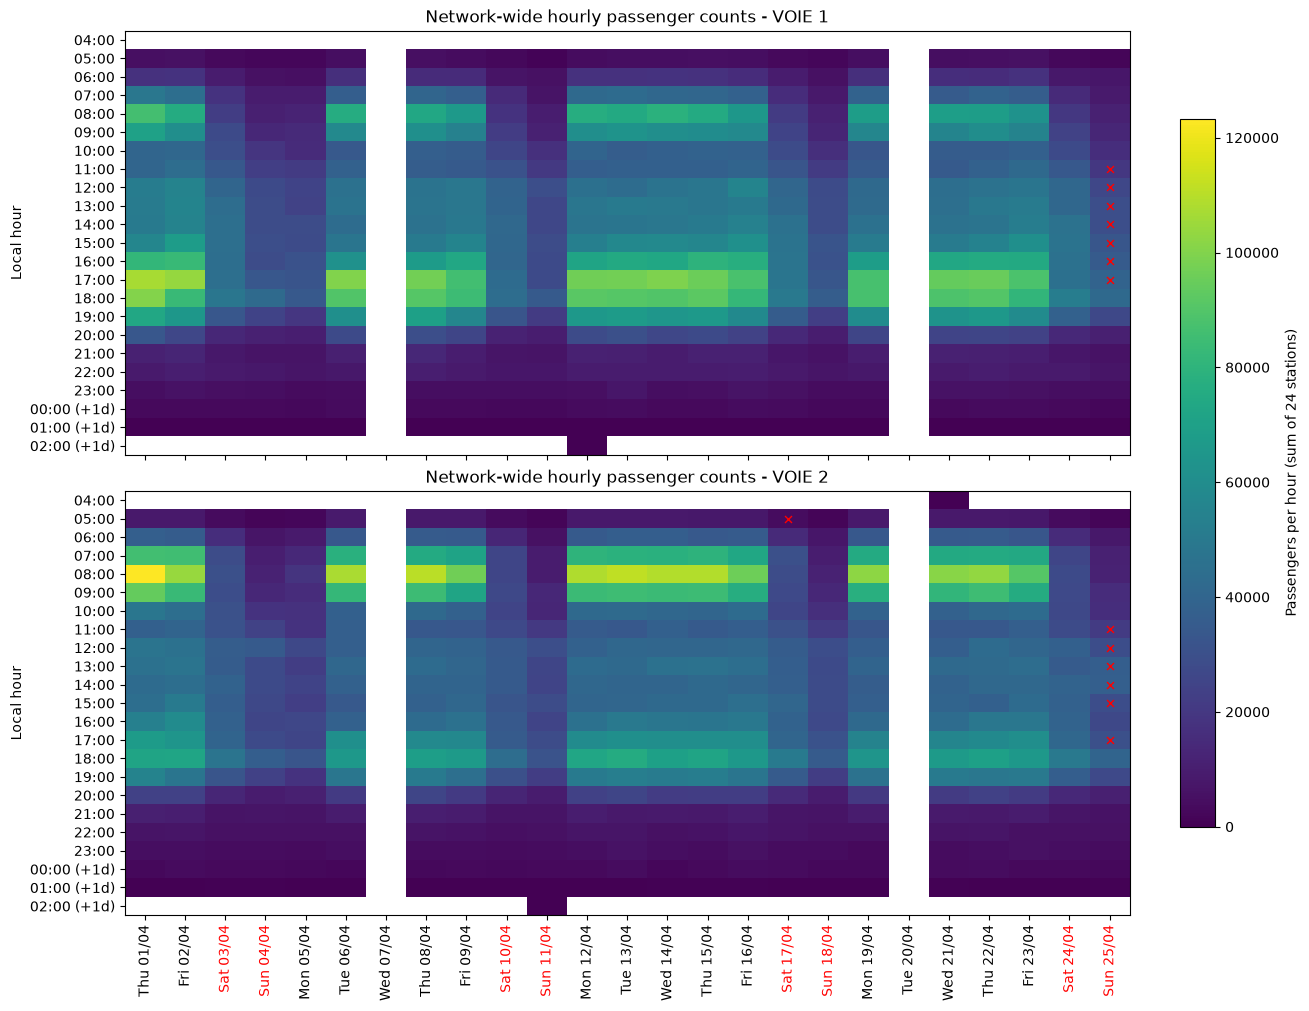

In [7]:
def network_hourly(hourly, regular):
    # Network-wide totals per (op_date, voie, hour) + number of stations recorded + completeness flag
    df = pd.DataFrame({"count": hourly.to_numpy(),
                       "observed": hourly.notna().to_numpy(),
                       "expected": expected_mask(hourly, regular)}, index=hourly.index)
    df["missing_expected"] = df["expected"] & ~df["observed"]
    g = df.groupby(level=["op_date", "voie", "hour"], sort=False)
    out = pd.DataFrame({"total": g["count"].sum(min_count=1),
                        "n_stations": g["observed"].sum(),
                        "n_missing_expected": g["missing_expected"].sum()})
    out["complete"] = out["n_missing_expected"] == 0
    return out


def plot_network_heatmaps(net, dates, hours):
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("white")
    vmax = net["total"].max()
    fig, axes = plt.subplots(len(VOIES), 1, figsize=(13, 10), sharex=True, constrained_layout=True)
    for ax, voie in zip(axes, VOIES):
        sub = net.xs(voie, level="voie")
        mat = sub["total"].unstack("op_date").reindex(index=hours, columns=dates)
        inc = (~sub["complete"]).unstack("op_date").reindex(index=hours, columns=dates).fillna(False)
        im = ax.imshow(np.ma.masked_invalid(mat.to_numpy(dtype=float)), aspect="auto", cmap=cmap,
                       vmin=0, vmax=vmax, interpolation="nearest")
        yy, xx = np.nonzero(inc.to_numpy(dtype=bool) & mat.notna().to_numpy())
        ax.scatter(xx, yy, marker="x", color="red", s=25, lw=1)
        set_hour_axis(ax, hours, axis="y")
        ax.set_ylabel("Local hour")
        ax.set_title(f"Network-wide hourly passenger counts - VOIE {voie}")
        ax.grid(False)
    ax.set_xticks(range(len(dates)), [f"{d:%a %d/%m}" for d in dates], rotation=90)
    for lbl, d in zip(ax.get_xticklabels(), dates):
        if d.dayofweek >= 5:
            lbl.set_color("red")
    fig.colorbar(im, ax=axes, label="Passengers per hour (sum of 24 stations)", shrink=0.8)
    return fig


net_train = network_hourly(hourly_train, regular_train)
fig = plot_network_heatmaps(net_train, TRAIN_DATES, HOURS)
save_fig(fig, "1_1_network_heatmaps")
plt.show()

In [8]:
# Mean network profile per direction and day type (complete cells only)
tbl = net_train[net_train["complete"]].reset_index()
tbl["day_type"] = day_type(tbl["op_date"])
mean_net = tbl.groupby(["voie", "day_type", "hour"])["total"].mean().unstack("hour").reindex(columns=HOURS)
print(mean_net.rename(columns=hour_label).round(0).to_string())
print("\nPeak hour of the mean profile:")
print(mean_net.idxmax(axis=1).map(hour_label))

hour           04:00   05:00    06:00    07:00    08:00    09:00    10:00    11:00    12:00    13:00    14:00    15:00    16:00    17:00    18:00    19:00    20:00    21:00   22:00   23:00  00:00 (+1d)  01:00 (+1d)  02:00 (+1d)
voie day_type                                                                                                                                                                                                                      
1    weekday     NaN  4643.0  16022.0  38102.0  68795.0  56726.0  35812.0  37052.0  46277.0  47380.0  47599.0  54080.0  71235.0  91118.0  85143.0  61219.0  26006.0  10826.0  9064.0  5207.0       3352.0         18.0         33.0
     weekend     NaN  2280.0   7144.0  12026.0  15611.0  18648.0  22380.0  28052.0  35201.0  35821.0  37536.0  38637.0  37900.0  39384.0  43782.0  29516.0  11948.0   6936.0  7936.0  4702.0       2840.0         24.0          NaN
2    weekday    22.0  7876.0  33453.0  73447.0  99452.0  77706.0  40002.0  34505.0  3979

**Observations**
- Weekdays show two daily peaks in both directions: a morning peak at 08:00–09:00 and an afternoon peak at 17:00–18:00; weekends have a single, flatter plateau from late morning to about 18:00, peaking around 18:00.
- The directions are mirror images: VOIE 2 has the stronger morning peak (≈ 99 000 pass./h at 08:00 on average weekdays vs ≈ 69 000 for VOIE 1), while VOIE 1 has the stronger afternoon peak (≈ 91 000 at 17:00 vs ≈ 67 000 at 18:00 for VOIE 2). The VOIE 2 evening peak is also about one hour later (18:00) than the VOIE 1 one (17:00).
- Demand falls sharply after 19:00–20:00 in both directions; 00:00–02:00 (+1d) and 04:00–05:00 carry very little demand.
- Exceptions: Monday 5 April looks like a Sunday (no commuting peaks); 7 and 20 April have no records at all (blank columns); Sunday 25 April is incomplete (station 12 missing 11:00–17:00, `×`); 01:00 (+1d) and 02:00 (+1d) are recorded only by a few stations, so these rows are sparse by construction.
- The first two days (1–2 April) have the highest peaks of the period; the level is otherwise stable from week to week.

**Possible explanations:** the opposite peak directions suggest that VOIE 2 points towards the main employment/activity area (morning inbound) and VOIE 1 away from it (evening return). 5 April 2021 was Easter Monday (public holiday). The early drop after 19:00 is consistent with an evening curfew that was in force in spring 2021, and the higher 1–2 April levels could be linked to the change of sanitary restrictions/school holidays starting in early April.

## 1.2 Compare daily totals and weekly patterns

Daily total = sum of the network-wide hourly counts over all recorded hours of the operating day, per direction.
Incomplete days are shown with hollow markers and left out of the day-of-week distributions.

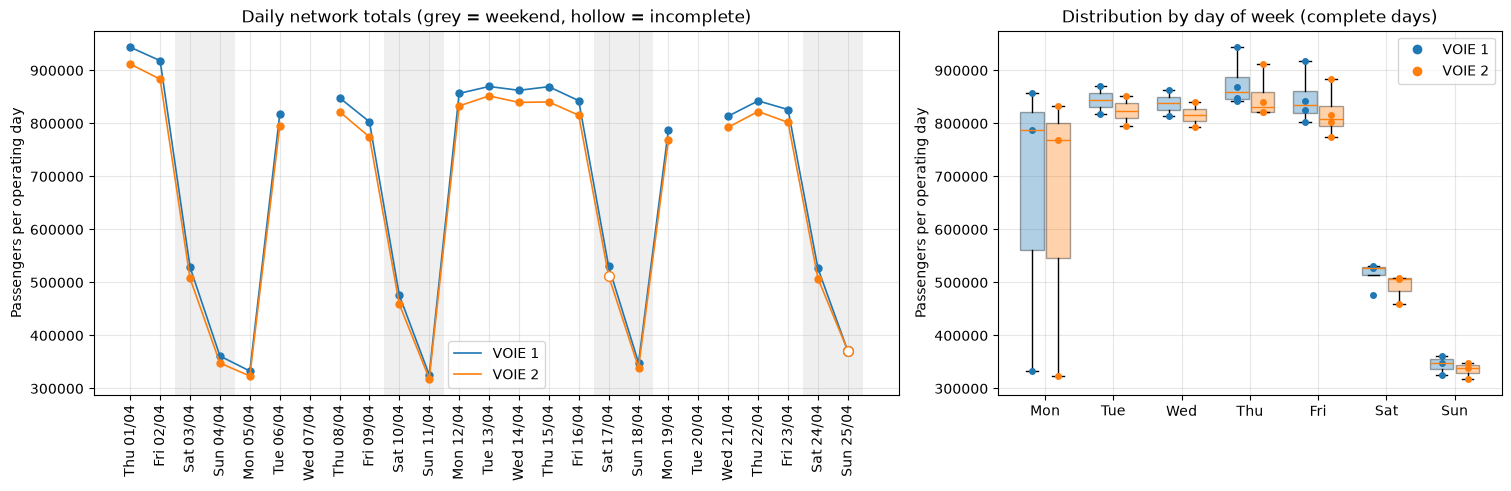

In [ ]:
def daily_totals(net):
    g = net.groupby(level=["op_date", "voie"])
    out = pd.DataFrame({"total": g["total"].sum(min_count=1),
                        "n_missing_expected": g["n_missing_expected"].sum()})
    out["complete"] = out["n_missing_expected"] == 0
    dates = out.index.get_level_values("op_date")
    out["weekday"] = dates.dayofweek
    out["day_type"] = day_type(dates)
    return out


daily_train = daily_totals(net_train)
daily_wide = daily_train["total"].unstack("voie")
complete_wide = daily_train["complete"].unstack("voie")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]},
                               constrained_layout=True)

# a) daily series on the full calendar (gaps for dates without records)
for voie in VOIES:
    s = daily_wide[voie].reindex(TRAIN_DATES)
    ok = complete_wide[voie].reindex(TRAIN_DATES).fillna(False).astype(bool)
    ax1.plot(s.index, s, color=VOIE_COLORS[voie], lw=1.2, label=f"VOIE {voie}")
    ax1.plot(s.index[ok], s[ok], "o", color=VOIE_COLORS[voie], ms=5)
    ax1.plot(s.index[~ok], s[~ok], "o", mfc="white", mec=VOIE_COLORS[voie], ms=7)
for d in dates_of_type(TRAIN_DATES, "weekend"):
    ax1.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color="grey", alpha=0.12, lw=0)
ax1.set_xticks(TRAIN_DATES, [f"{d:%a %d/%m}" for d in TRAIN_DATES], rotation=90)
ax1.set_ylabel("Passengers per operating day")
ax1.set_title("Daily network totals (grey = weekend, hollow = incomplete)")
ax1.legend()

# b) distribution by day of week, complete days only
ok_days = daily_train[daily_train["complete"]].reset_index()
width = 0.38
for k, voie in enumerate(VOIES):
    data = [ok_days.loc[(ok_days.voie == voie) & (ok_days.weekday == wd), "total"].to_numpy() for wd in range(7)]
    pos = np.arange(7) + (k - 0.5) * width
    bp = ax2.boxplot(data, positions=pos, widths=width * 0.9, patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set_facecolor(VOIE_COLORS[voie])
        patch.set_alpha(0.35)
    for p, vals in zip(pos, data):
        ax2.plot(np.full(len(vals), p), vals, "o", color=VOIE_COLORS[voie], ms=4)
ax2.set_xticks(range(7), WEEKDAY_NAMES)
ax2.set_ylabel("Passengers per operating day")
ax2.set_title("Distribution by day of week (complete days)")
ax2.legend(handles=[Line2D([], [], color=VOIE_COLORS[v], marker="o", lw=0, label=f"VOIE {v}") for v in VOIES])
save_fig(fig, "1_2_daily_totals")
plt.show()

In [10]:
print("Complete days per weekday and direction:")
print(ok_days.groupby(["voie", "weekday"]).size().unstack("weekday").rename(columns=dict(enumerate(WEEKDAY_NAMES))))

summary_daytype = ok_days.groupby(["day_type", "voie"])["total"].agg(["count", "mean", "std", "min", "max"]).round(0)
print("\nDaily totals by day type and direction (complete days):")
print(summary_daytype)
print("\nWeekend / weekday mean ratio:",
      (summary_daytype["mean"]["weekend"] / summary_daytype["mean"]["weekday"]).round(3).to_dict())

ratio = (daily_wide[1] / daily_wide[2])[complete_wide.all(axis=1)]
print("\nRatio VOIE 1 / VOIE 2 of daily totals (days complete in both directions):")
print(ratio.groupby(day_type(ratio.index)).describe().round(3))

print("\nIncomplete days:")
print(daily_train[~daily_train["complete"] & daily_train["total"].notna()][["total", "n_missing_expected"]])

Complete days per weekday and direction:
weekday  Mon  Tue  Wed  Thu  Fri  Sat  Sun
voie                                      
1          3    2    2    4    4    4    3
2          3    2    2    4    4    3    3

Daily totals by day type and direction (complete days):
               count      mean       std       min       max
day_type voie                                               
weekday  1        15  815682.0  139695.0  332880.0  943706.0
         2        15  791846.0  135067.0  323553.0  911922.0
weekend  1         7  442344.0   93500.0  325508.0  530275.0
         2         6  413303.0   87774.0  318764.0  507720.0

Weekend / weekday mean ratio: {1: 0.542, 2: 0.522}

Ratio VOIE 1 / VOIE 2 of daily totals (days complete in both directions):
         count   mean    std    min    25%    50%    75%    max
weekday   15.0  1.030  0.005  1.021  1.027  1.029  1.034  1.039
weekend    6.0  1.034  0.008  1.021  1.030  1.037  1.038  1.041

Incomplete days:
                    total  

**Observations**
- Complete weekdays carry ≈ 815 000 (VOIE 1) and ≈ 790 000 (VOIE 2) passengers per day; weekends ≈ 440 000 / 415 000, so about 52–54 % of a weekday. Saturdays (≈ 475 000–530 000) are clearly higher than Sundays (≈ 320 000–360 000).
- Tuesday to Friday are very similar; Thursday and Friday 1–2 April are the highest days. The large spread on Mondays is entirely due to Easter Monday (≈ 330 000, Sunday level).
- VOIE 1 is systematically ≈ 3 % higher than VOIE 2 (daily ratio 1.02–1.04 on every complete day, weekdays and weekends). So over a whole day the directions almost balance, even though their hourly profiles are very different (1.1): the asymmetry is in timing, not in volume.
- Incomplete days: 25 April (both directions, station 12) and 17 April (VOIE 2, one station-hour) : their totals are under-estimates and are not used in the distributions.

**Possible explanations:** near-balanced daily totals are expected for round trips (people who leave in one direction come back in the other). The small but constant excess of VOIE 1 could come from the counting equipment, or from passengers using another mode for one leg of the trip; the data do not allow distinguishing these.

## 1.3 Hourly profiles across stations (VOIE 1)

Representative profile of station $s$: $\bar c_{s,h} = \frac{1}{|D_{s,h}|}\sum_{d\in D_{s,h}} c_{d,s,h}$, the mean over
the training dates $D_{s,h}$ on which interval $h$ was recorded (missing intervals are skipped, not counted as 0).

Normalization: each profile is divided by its own maximum, $\tilde c_{s,h} = \bar c_{s,h} / \max_{h'} \bar c_{s,h'}$,
so every profile peaks at 1. This removes the demand level of the station and keeps only the shape of the profile
(peak timing and relative size of the morning and evening peaks).

Number of training dates behind each hourly mean (min / max over stations):
hour  04:00  05:00  06:00  07:00  08:00  09:00  10:00  11:00  12:00  13:00  14:00  15:00  16:00  17:00  18:00  19:00  \
min       0     23     23     23     23     23     23     22     22     22     22     22     22     22     23     23   
max       0     23     23     23     23     23     23     23     23     23     23     23     23     23     23     23   

hour  20:00  21:00  22:00  23:00  00:00 (+1d)  01:00 (+1d)  02:00 (+1d)  
min      23     23     23     23           23            0            0  
max      23     23     23     23           23           23            1  


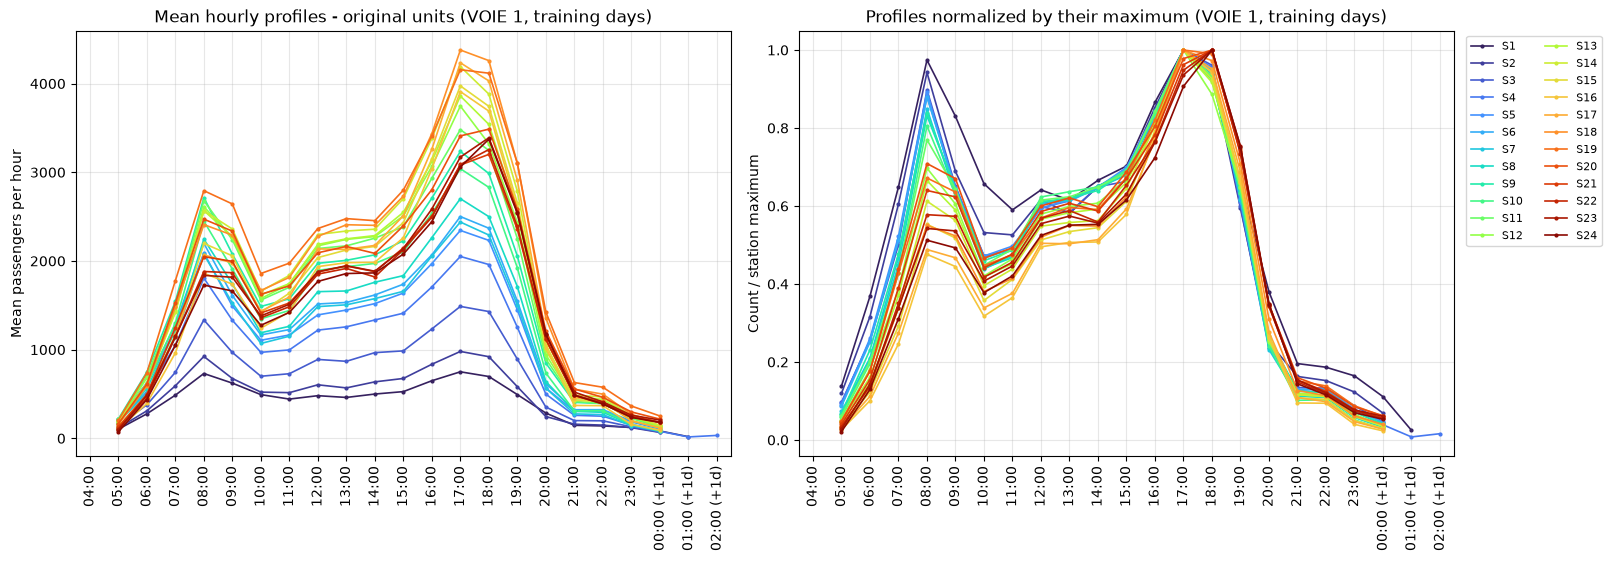

In [11]:
def mean_profiles(hourly, hours, by="station"):
    # Mean count per hour (NaN skipped) for each group + number of dates used per hour
    g = hourly.groupby(level=[by, "hour"])
    return g.mean().unstack("hour").reindex(columns=hours), g.count().unstack("hour").reindex(columns=hours)


def normalize_by_max(profiles):
    return profiles.div(profiles.max(axis=1), axis=0)


def peak_summary(profiles, hours, split_hour=12):
    # Morning (before split_hour) and afternoon peaks of each profile (one row per profile)
    am = [h for h in hours if opday_position(h) < opday_position(split_hour)]
    pm = [h for h in hours if opday_position(h) >= opday_position(split_hour)]
    out = pd.DataFrame(index=profiles.index)
    out["daily_sum"] = profiles.sum(axis=1, min_count=1)
    out["am_peak_hour"] = profiles[am].idxmax(axis=1).map(hour_label)
    out["am_peak"] = profiles[am].max(axis=1)
    out["pm_peak_hour"] = profiles[pm].idxmax(axis=1).map(hour_label)
    out["pm_peak"] = profiles[pm].max(axis=1)
    out["am_pm_ratio"] = out["am_peak"] / out["pm_peak"]
    return out


profiles_v1, profiles_v1_n = mean_profiles(select(hourly_train, voies=[1]), HOURS)
profiles_v1_norm = normalize_by_max(profiles_v1)

print("Number of training dates behind each hourly mean (min / max over stations):")
print(pd.DataFrame({"min": profiles_v1_n.min(), "max": profiles_v1_n.max()}).T.rename(columns=hour_label))

station_colors = dict(zip(STATIONS, plt.cm.turbo(np.linspace(0.02, 0.98, len(STATIONS)))))
x = np.arange(len(HOURS))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), constrained_layout=True)
for ax, prof, title, ylabel in [
    (axes[0], profiles_v1, "Mean hourly profiles - original units", "Mean passengers per hour"),
    (axes[1], profiles_v1_norm, "Profiles normalized by their maximum", "Count / station maximum"),
]:
    for s in STATIONS:
        ax.plot(x, prof.loc[s], marker=".", ms=4, lw=1.2, color=station_colors[s], label=f"S{s}")
    set_hour_axis(ax, HOURS)
    ax.set_title(f"{title} (VOIE 1, training days)")
    ax.set_ylabel(ylabel)
axes[1].legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "1_3_station_profiles")
plt.show()

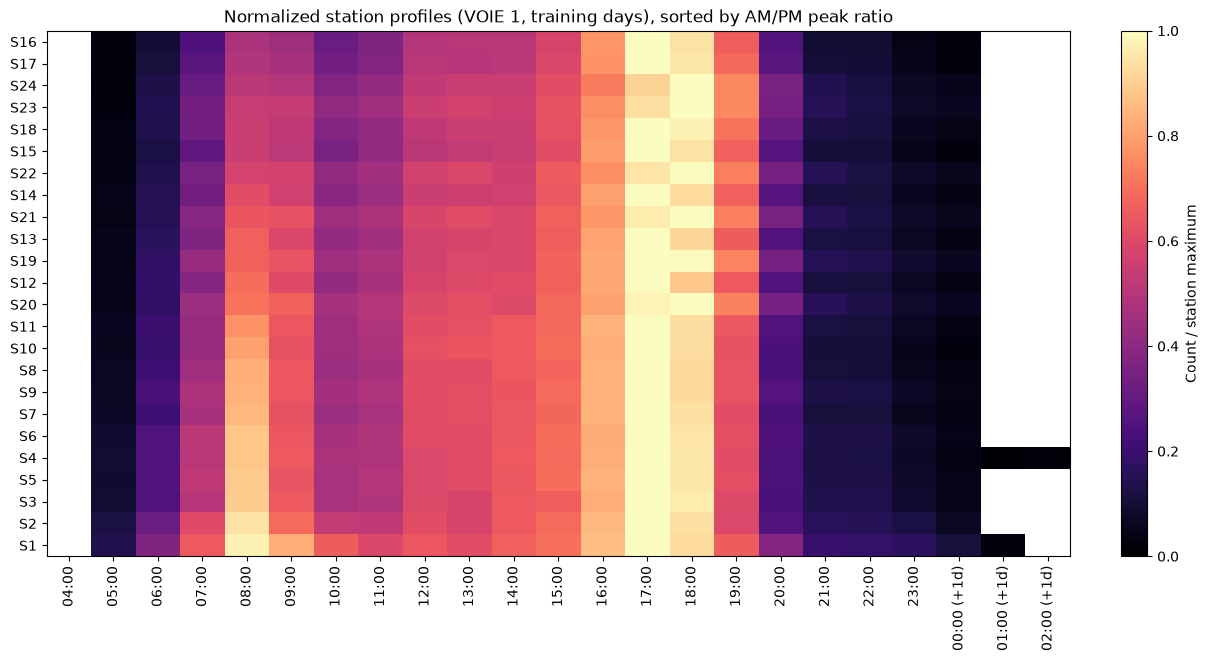

         daily_sum am_peak_hour  am_peak pm_peak_hour  pm_peak  am_pm_ratio
station                                                                    
16        31137.13        08:00  1861.04        17:00  3910.09         0.48
17        34586.83        08:00  2068.13        17:00  4234.91         0.49
24        29097.96        08:00  1728.22        18:00  3373.91         0.51
23        30393.26        08:00  1838.04        18:00  3388.65         0.54
18        38261.48        08:00  2410.13        17:00  4378.78         0.55
15        33596.61        08:00  2197.91        17:00  3974.09         0.55
22        29652.22        08:00  1881.35        18:00  3256.57         0.58
14        37043.04        08:00  2566.57        17:00  4191.65         0.61
21        30285.78        08:00  2048.74        18:00  3202.00         0.64
13        35070.43        08:00  2568.00        17:00  3860.17         0.67
19        40119.09        08:00  2792.70        17:00  4156.74         0.67
12        34

In [12]:
# Normalized profiles as a heatmap, stations sorted by their morning/afternoon peak ratio
peaks_v1 = peak_summary(profiles_v1, HOURS)
order = peaks_v1.sort_values("am_pm_ratio").index

cmap = plt.get_cmap("magma").copy()
cmap.set_bad("white")
fig, ax = plt.subplots(figsize=(12, 6.5), constrained_layout=True)
im = ax.imshow(np.ma.masked_invalid(profiles_v1_norm.loc[order].to_numpy(dtype=float)),
               aspect="auto", cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
set_hour_axis(ax, HOURS)
ax.set_yticks(range(len(order)), [f"S{s}" for s in order])
ax.set_title("Normalized station profiles (VOIE 1, training days), sorted by AM/PM peak ratio")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Count / station maximum")
save_fig(fig, "1_3_station_profiles_norm_heatmap")
plt.show()

print(peaks_v1.loc[order].round(2).to_string())

**Observations**
- Original units: demand levels differ by a factor of ≈ 5 between stations (daily sum ≈ 8 500 at S1 vs ≈ 40 000 at S19); stations 1-3 are clearly the smallest, stations 14–19 the largest. Differences between stations are largest at the afternoon peak.
- Normalized: once the level is removed, all stations share the same timing — morning peak at 08:00, afternoon peak at 17:00 or 18:00, midday trough at 10:00–11:00, steep drop at 20:00. This common shape was hidden by the level differences in the original plot.
- What normalization reveals as a real difference is the relative strength of the two peaks (AM/PM ratio): ≈ 0.8–1.0 for stations 1–9 (balanced peaks), ≈ 0.5–0.6 for stations 15–18 and 22–24 (afternoon peak about twice the morning one); intermediate stations (10–14, 19–21) lie in between. The ratio varies almost monotonically with the station number.
- Differences that disappear with normalization: the absolute level of each station and the absolute gap between stations at the peaks. Hours 01:00–02:00 (+1d) are based on 1–2 dates only.

**Possible explanations:** if station numbers follow the order along the line, VOIE 1 passengers boarding at the low-numbered stations travel in both peaks (residential and activity uses mixed), while at the high-numbered stations VOIE 1 boardings are mostly an evening return trip.

## 1.4 Compare weekday and weekend station profiles (stations 1, 7, 16, 19; VOIE 1)

For each station and day type: mean over training dates at each hour; band = mean ± 1 standard deviation across dates.

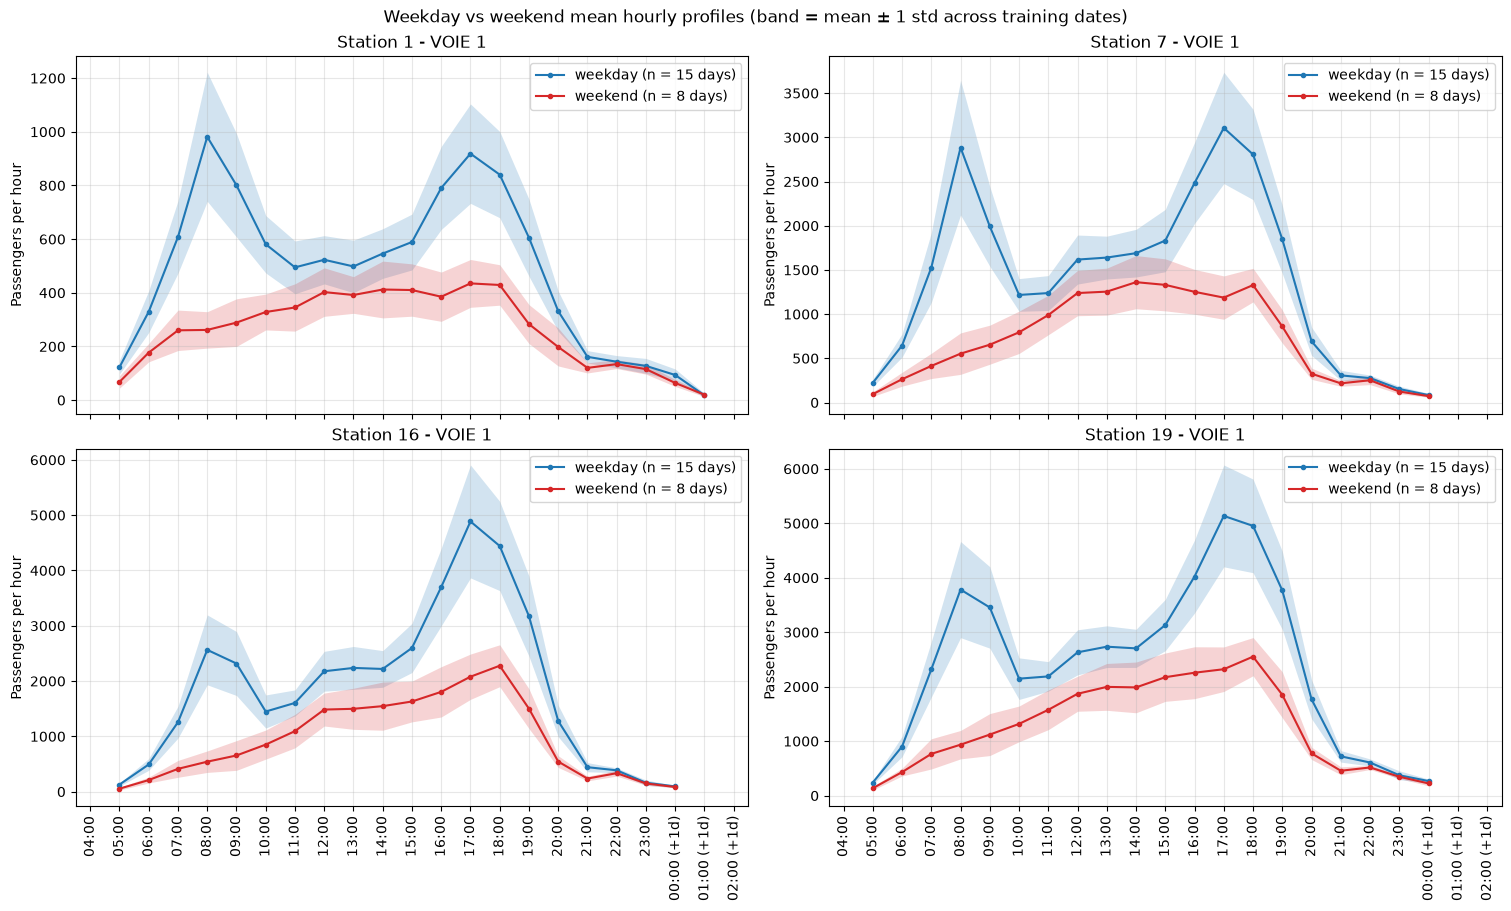

                  daily_sum am_peak_hour  am_peak pm_peak_hour  pm_peak  am_pm_ratio  mean_rel_std
station day_type                                                                                  
1       weekday    10104.73        08:00   981.40        17:00   918.53         1.07          0.21
        weekend     5530.62        11:00   345.25        17:00   435.00         0.79          0.24
7       weekday    28262.53        08:00  2884.13        17:00  3107.00         0.93          0.19
        weekend    14568.75        11:00   989.75        14:00  1361.62         0.73          0.24
16      weekday    37614.73        08:00  2564.40        17:00  4886.60         0.52          0.20
        weekend    18991.62        11:00  1094.88        18:00  2277.50         0.48          0.26
19      weekday    47855.73        08:00  3783.20        17:00  5135.80         0.74          0.17
        weekend    25612.88        11:00  1575.75        18:00  2551.88         0.62          0.21


In [13]:
FOCUS_STATIONS = [1, 7, 16, 19]


def profile_stats(hourly, hours):
    # Mean, std (across dates, ddof=1) and number of dates per hour
    g = hourly.groupby(level="hour")
    return pd.DataFrame({"mean": g.mean(), "std": g.std(ddof=1), "n": g.count()}).reindex(hours)


def plot_band(ax, stats, label, color):
    # Mean line + mean +/- 1 std band; NaN hours leave gaps
    x = np.arange(len(stats))
    ax.plot(x, stats["mean"], marker="o", ms=3, color=color, label=label)
    ax.fill_between(x, stats["mean"] - stats["std"], stats["mean"] + stats["std"], color=color, alpha=0.2, lw=0)


fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, constrained_layout=True)
rows = []
for ax, s in zip(axes.ravel(), FOCUS_STATIONS):
    for kind in ["weekday", "weekend"]:
        st = profile_stats(select(hourly_train, dates=dates_of_type(TRAIN_DATES, kind), stations=[s], voies=[1]), HOURS)
        plot_band(ax, st, f"{kind} (n = {st['n'].max()} days)", DAYTYPE_COLORS[kind])
        pk = peak_summary(st[["mean"]].T, HOURS).iloc[0]
        rows.append({"station": s, "day_type": kind, **pk.to_dict(),
                     "mean_rel_std": (st["std"] / st["mean"]).mean()})
    set_hour_axis(ax, HOURS)
    ax.set_title(f"Station {s} - VOIE 1")
    ax.set_ylabel("Passengers per hour")
    ax.legend()
fig.suptitle("Weekday vs weekend mean hourly profiles (band = mean ± 1 std across training dates)")
save_fig(fig, "1_4_weekday_weekend_profiles")
plt.show()

print(pd.DataFrame(rows).set_index(["station", "day_type"]).round(2).to_string())

**Observations**
- Weekdays: two peaks at 08:00 and 17:00 at all four stations. Weekends: no morning peak, demand rises gradually to a broad plateau between 12:00 and 18:00 (peak hour 14:00–18:00).
- Weekend demand is about half the weekday one (daily sum ratio ≈ 0.51–0.55); the difference is concentrated in the peaks, while late-evening (after 21:00) counts are almost identical.
- Relative peak strength differs by station: on weekdays S1 has a slightly stronger morning peak (AM/PM ≈ 1.07), S7 has balanced peaks (0.93), S19 (0.74) and S16 (0.52) are afternoon-dominated.
- Variability: the weekday bands are widest at the peaks (relative std ≈ 0.17–0.21), partly inflated by Easter Monday; weekend bands are narrower in absolute value but relatively larger (≈ 0.21–0.26), reflecting Saturday/Sunday differences.

**Possible explanation:** weekday peaks are driven by commuting (work/school); weekend trips are more discretionary (shopping, leisure), spread over the day.

## 1.5 Examine directional differences at stations (weekdays)

Same statistics as in 1.4, comparing VOIE 1 and VOIE 2 on the training weekdays.

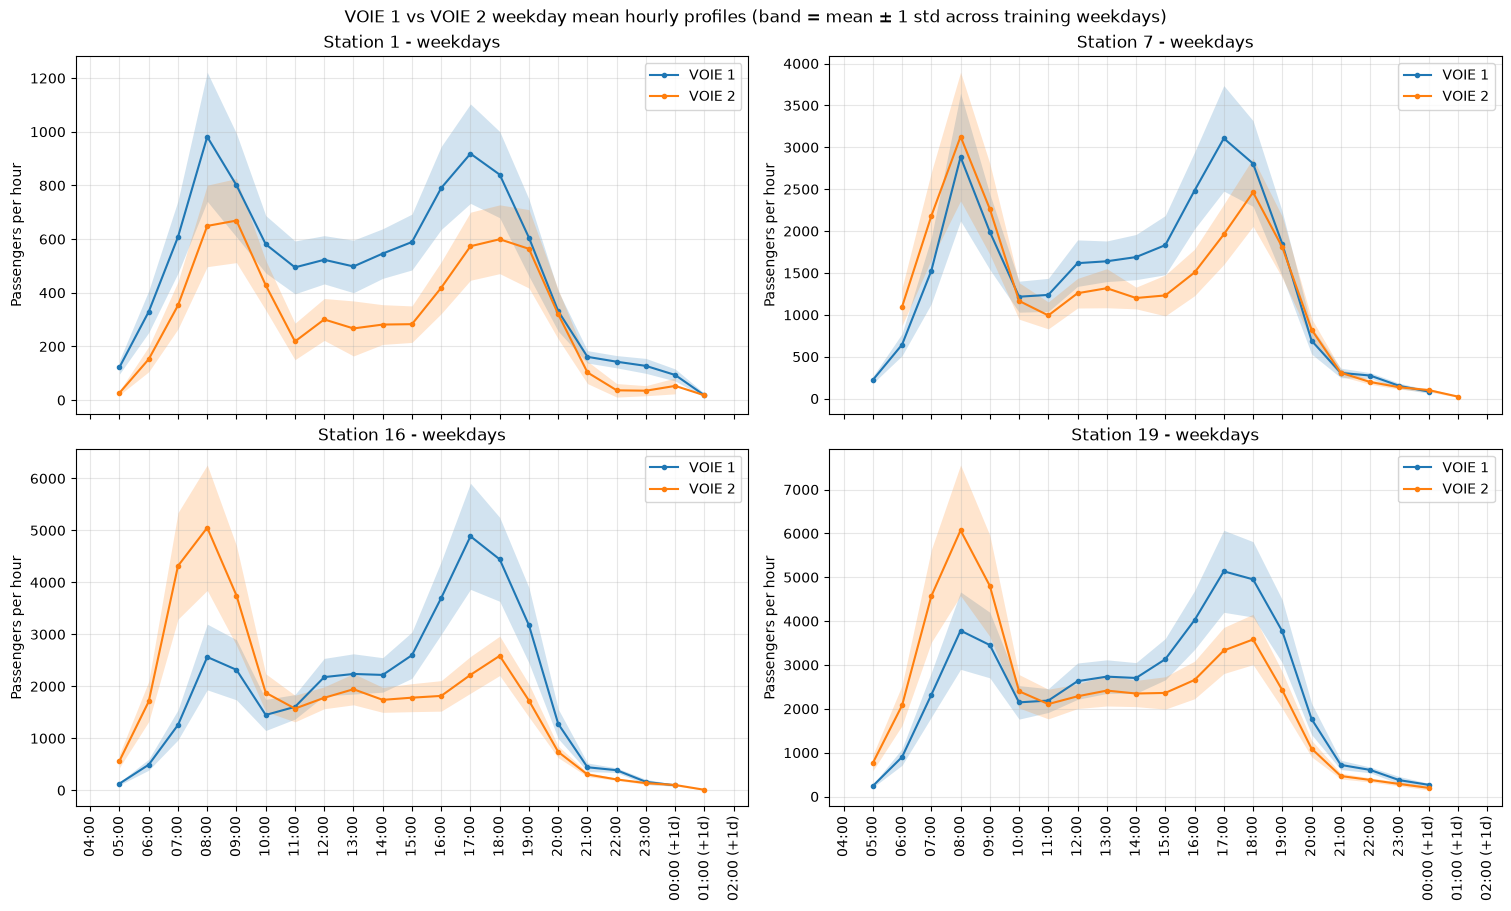

In [14]:
TRAIN_WEEKDAYS = dates_of_type(TRAIN_DATES, "weekday")

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, constrained_layout=True)
dir_stats = {}
for ax, s in zip(axes.ravel(), FOCUS_STATIONS):
    for voie in VOIES:
        st = profile_stats(select(hourly_train, dates=TRAIN_WEEKDAYS, stations=[s], voies=[voie]), HOURS)
        dir_stats[(s, voie)] = st
        plot_band(ax, st, f"VOIE {voie}", VOIE_COLORS[voie])
    set_hour_axis(ax, HOURS)
    ax.set_title(f"Station {s} - weekdays")
    ax.set_ylabel("Passengers per hour")
    ax.legend()
fig.suptitle("VOIE 1 vs VOIE 2 weekday mean hourly profiles (band = mean ± 1 std across training weekdays)")
save_fig(fig, "1_5_directional_profiles")
plt.show()

         daily V1  daily V2  share V1 (day)  early 05-07  AM peak 07-09  midday 09-16  PM peak 16-19  evening 19-01
station                                                                                                            
1        10104.73   6351.71            0.61         0.72           0.61          0.62           0.62           0.57
7        28262.53  25175.73            0.53         0.44           0.45          0.54           0.59           0.50
16       37614.73  35931.27            0.51         0.21           0.29          0.50           0.66           0.63
19       47855.73  46635.73            0.51         0.29           0.36          0.50           0.60           0.61


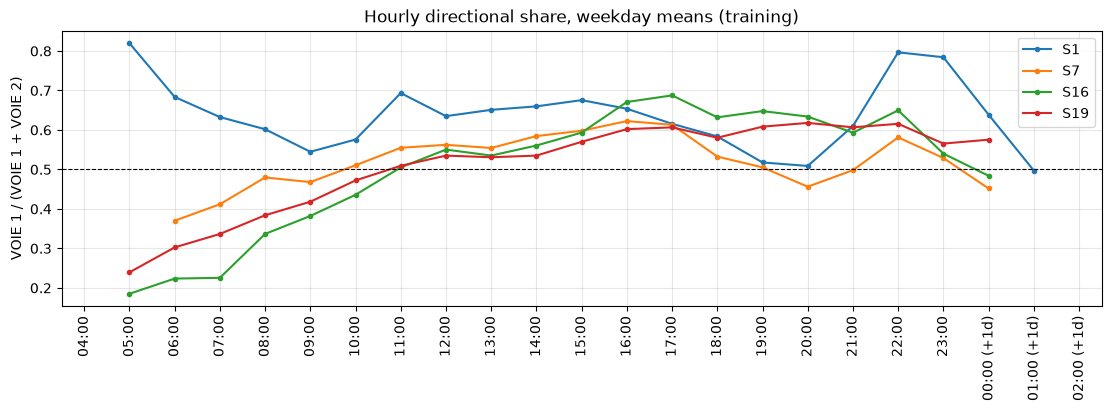

In [15]:
# Share of VOIE 1 in the two-direction total of the weekday mean profile, by period of the day (0.5 = symmetric)
PERIODS = {"early 05-07": [5, 6], "AM peak 07-09": [7, 8], "midday 09-16": list(range(9, 16)),
           "PM peak 16-19": [16, 17, 18], "evening 19-01": [19, 20, 21, 22, 23, 0]}
rows = []
for s in FOCUS_STATIONS:
    m1, m2 = dir_stats[(s, 1)]["mean"], dir_stats[(s, 2)]["mean"]
    row = {"station": s, "daily V1": m1.sum(), "daily V2": m2.sum(), "share V1 (day)": m1.sum() / (m1.sum() + m2.sum())}
    row.update({name: m1[hs].sum() / (m1[hs].sum() + m2[hs].sum()) for name, hs in PERIODS.items()})
    rows.append(row)
print(pd.DataFrame(rows).set_index("station").round(2).to_string())

fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for s in FOCUS_STATIONS:
    m1, m2 = dir_stats[(s, 1)]["mean"], dir_stats[(s, 2)]["mean"]
    ax.plot(np.arange(len(HOURS)), (m1 / (m1 + m2)).to_numpy(), marker="o", ms=3, label=f"S{s}")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
set_hour_axis(ax, HOURS)
ax.set_ylabel("VOIE 1 / (VOIE 1 + VOIE 2)")
ax.set_title("Hourly directional share, weekday means (training)")
ax.legend()
save_fig(fig, "1_5_directional_share")
plt.show()

**Observations**
- **Station 1**: VOIE 1 dominates at almost every hour (≈ 61 % of the daily total), with both peaks higher in VOIE 1.
- **Station 7**: nearly symmetric (VOIE 1 share ≈ 53 %): VOIE 2 slightly higher in the morning (45 % VOIE 1 at 07–09), VOIE 1 higher in the afternoon (59 % at 16–19).
- **Stations 16 and 19**: daily totals are balanced (≈ 51 % VOIE 1) but the asymmetry is strong and reverses during the day: VOIE 2 dominates the morning (VOIE 1 share only 21–36 % before 09:00; VOIE 2 peak ≈ 5 000–6 000 pass./h at 08:00), VOIE 1 dominates the afternoon (60–66 %).
- Midday (10:00–15:00) is the most symmetric period at all stations; variability bands of the dominant direction are the widest at its peak.
- So yes: directional asymmetry depends both on the station and on the time of day, and it grows with the station number.

**Possible explanation:** stations 16/19 behave like origins of tidal commuting (outbound towards the activity area in the morning on VOIE 2, return on VOIE 1 in the evening), while station 1 may be close to a terminus or a major activity zone where one direction is used more in both peaks. These are hypotheses: line geometry and land use are not in the data.

## 2) Clustering Dates and Stations

Three observations from Section 1 guide the choice of the representations:

1. **Volume matters for dates.** A weekend day carries only ≈ 52–54 % of a weekday (1.2) and has no commuting peaks (1.4), so the date features must keep the volume and not only the shape.
2. **The calendar is not the whole story.** Easter Monday (5 April) looked like a Sunday (1.1) and 25 April is incomplete. We let the clustering tell which dates behave alike, instead of imposing weekday / weekend.
3. **Stations differ in level (factor ≈ 5) and in the balance between morning and afternoon peak, but not in peak timing** (1.3). For the stations we keep level and shape together (weekday and weekend means), and then check what changes if only the shape is kept.

Settings for the whole section: training dates only, VOIE 1, the 19 hourly intervals 06:00 → 00:00 (+1d) (so 04:00, 05:00, 01:00 (+1d) and 02:00 (+1d) are dropped), raw counts (no normalization), Ward linkage with Euclidean distance (`scipy`).

### Retained dates and stations, incomplete profiles

A station profile of one date is *complete* when its 19 hours are all observed. The feature matrices must not contain missing values and a missing hour is **not** a zero, so we look at what is missing first.

In [16]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score

# the 19 intervals of Section 2: 06:00 -> 00:00 (+1d)
H19 = HOURS[HOURS.index(6): HOURS.index(0) + 1]
print(len(H19), "intervals:", hour_label(H19[0]), "->", hour_label(H19[-1]))

# VOIE 1, training dates: one row per (date, station), one column per hour
prof_all = select(hourly_train, voies=[1], hours=H19).droplevel("voie").unstack("hour")[H19]

# number of missing hours (out of 19) for each (date, station)
n_missing = prof_all.isna().sum(axis=1)
bad = n_missing[n_missing > 0].groupby(level="op_date").agg(["count", "sum"])
bad.columns = ["stations_incomplete", "missing_hours"]
print("\nDates with at least one incomplete station profile:")
print(bad.rename(index=lambda d: f"{d:%a %d %b}"))

# a date is kept only if its 24 station profiles are all complete
date_ok = (n_missing == 0).groupby(level="op_date").all()
DATES_2 = date_ok.index[date_ok]
print("\nRetained dates:", len(DATES_2), "of", len(TRAIN_DATES),
      "-> weekdays / weekend days:", len(dates_of_type(DATES_2, "weekday")), "/", len(dates_of_type(DATES_2, "weekend")))
print("Excluded dates:", [f"{d:%a %d %b}" for d in TRAIN_DATES.difference(DATES_2)])
print("Retained stations:", len(STATIONS), "(all of them) ->", STATIONS)

19 intervals: 06:00 -> 00:00 (+1d)

Dates with at least one incomplete station profile:
            stations_incomplete  missing_hours
op_date                                       
Wed 07 Apr                   24            456
Tue 20 Apr                   24            456
Sun 25 Apr                    1              7

Retained dates: 22 of 25 -> weekdays / weekend days: 15 / 7
Excluded dates: ['Wed 07 Apr', 'Tue 20 Apr', 'Sun 25 Apr']
Retained stations: 24 (all of them) -> [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]


Only three dates are affected: 7 and 20 April have no record at all, and on 25 April station 12 misses 7 consecutive hours (11:00–17:00). We **exclude** these three dates and do not impute: the 25 April hole is a block of 7 hours in the middle of the day, exactly where a guess would be least reliable, and losing one date out of 23 is cheap. Excluding complete dates (and not only the incomplete station) keeps one common set of **22 dates** for 2.1 and 2.2, and all 24 stations are retained. Nothing is replaced by zero.

## 2.1 Cluster operating dates

Representation: the date $d$ is described by its 24 station profiles put one after the other,
$x_d = (c_{d,1,1},\dots,c_{d,1,T},\ c_{d,2,1},\dots,c_{d,S,T})$ with $S = 24$ and $T = 19$, in **raw passengers per hour**. We keep the raw counts on purpose: the weekday / weekend difference of Section 1 is mostly a difference of volume, and dividing each date by its total would erase it. (A shape-only version is tested at the end as a check.) With Ward linkage and Euclidean distance, the stations with large counts weigh more, which is fine here because they are also the ones that carry the contrast between date types.

In [17]:
S, T = len(STATIONS), len(H19)


def date_matrix(prof, dates):
    # one row per date: profile of station 1, then station 2, ... (S*T values)
    return np.vstack([prof.loc[d].loc[STATIONS].to_numpy().ravel() for d in dates])


X_dates = date_matrix(prof_all, DATES_2)
print(f"X_dates: N = {X_dates.shape[0]} dates x S*T = {S}*{T} = {S * T} columns -> shape {X_dates.shape}")
print("Missing values:", int(np.isnan(X_dates).sum()))

Z_dates = linkage(X_dates, method="ward", metric="euclidean")


def candidate_scores(X, Z, ks):
    # quality of the partitions obtained by cutting the dendrogram in k clusters
    n = len(X)
    tss = ((X - X.mean(axis=0)) ** 2).sum()
    rows = []
    for k in ks:
        lab = fcluster(Z, k, criterion="maxclust")
        wss = sum(((X[lab == c] - X[lab == c].mean(axis=0)) ** 2).sum() for c in np.unique(lab))
        rows.append({"k": k,
                     "silhouette": silhouette_score(X, lab),
                     "calinski_harabasz": calinski_harabasz_score(X, lab),
                     "davies_bouldin": davies_bouldin_score(X, lab),
                     "within_share": wss / tss,              # within-cluster SS / total SS
                     "merge_height": Z[n - k, 2],            # Ward cost of merging k clusters into k-1
                     "sizes": sorted(np.bincount(lab)[1:], reverse=True)})
    return pd.DataFrame(rows).set_index("k")


def plot_scores(scores, chosen, title):
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
    for ax, col, ylabel in zip(axes, ["silhouette", "within_share", "merge_height"],
                               ["Silhouette (higher = better)", "Within-cluster share of total variance",
                                "Ward merge height (k -> k-1 clusters)"]):
        ax.plot(scores.index, scores[col], marker="o")
        ax.axvline(chosen, color="k", ls="--", lw=0.8)
        ax.set_xlabel("Number of clusters k")
        ax.set_ylabel(ylabel)
    fig.suptitle(title)
    return fig


scores_dates = candidate_scores(X_dates, Z_dates, range(2, 9))
print(scores_dates.round(3).to_string())

X_dates: N = 22 dates x S*T = 24*19 = 456 columns -> shape (22, 456)
Missing values: 0


   silhouette  calinski_harabasz  davies_bouldin  within_share  merge_height                     sizes
k                                                                                                     
2       0.777            168.835           0.330         0.106     84424.302                   [14, 8]
3       0.747            158.645           0.317         0.056     19847.237                [14, 4, 4]
4       0.473            138.593           0.719         0.041     10936.321             [12, 4, 4, 2]
5       0.425            134.478           0.760         0.031      9304.552           [9, 4, 4, 3, 2]
6       0.422            124.572           0.588         0.025      6676.019        [9, 4, 4, 3, 1, 1]
7       0.381            121.147           0.761         0.020      6202.480     [5, 4, 4, 4, 3, 1, 1]
8       0.383            116.737           0.679         0.017      5186.830  [5, 4, 4, 3, 2, 2, 1, 1]


The silhouette is highest for k = 2 and almost as high for k = 3, then it drops clearly for k ≥ 4. The Davies–Bouldin index (lower = better) is best for k = 3 (0.317, against 0.330 for k = 2). The Calinski–Harabasz index only decreases with k, so it does not help to choose. The Ward merge height shows the biggest jump when going from 3 to 2 clusters and from 2 to 1 (the next ones are much smaller), which says that the data really contain **three** well-separated groups, k = 2 being the coarser version of the same structure. We keep **k = 3**: its silhouette is only slightly below k = 2 and the extra split is meaningful (see the observations below).

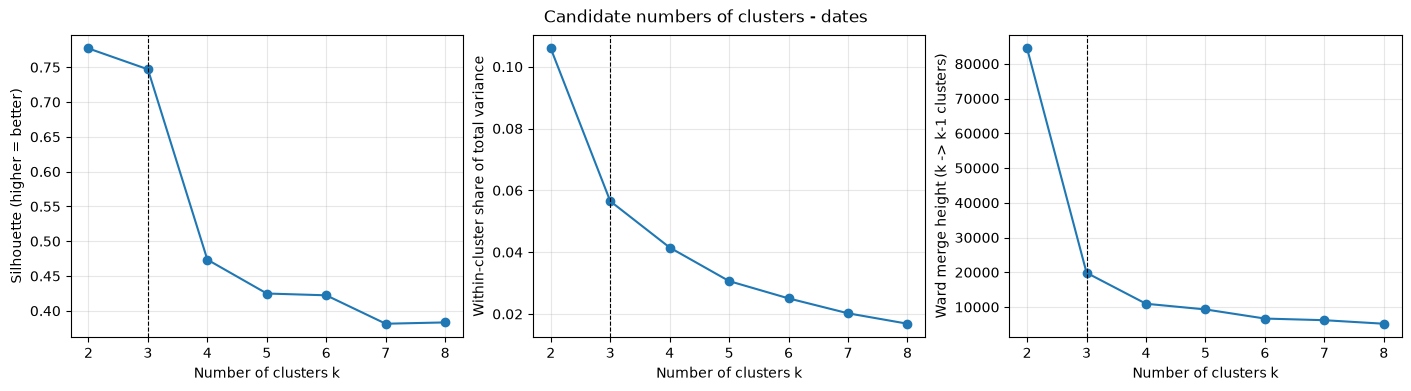

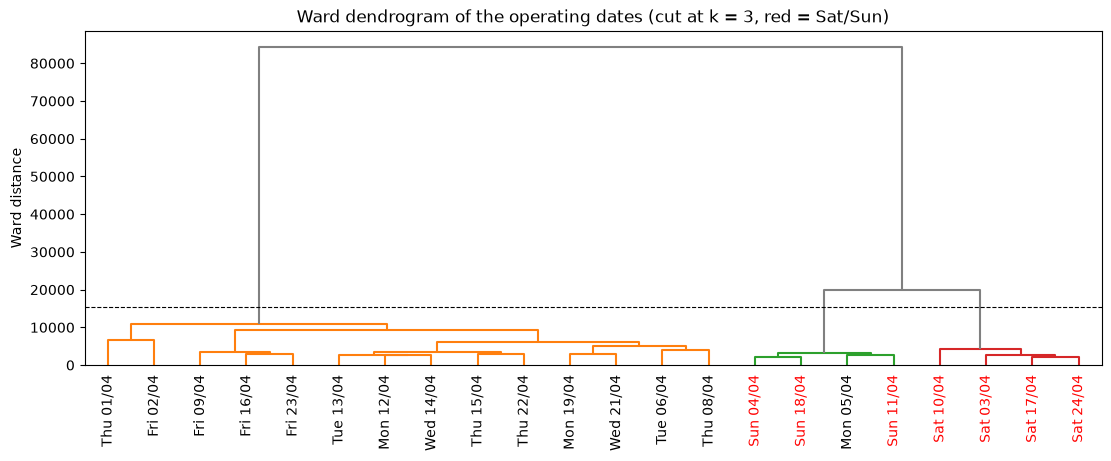

In [18]:
K_DATES = 3     # chosen after looking at the table above

fig = plot_scores(scores_dates, K_DATES, "Candidate numbers of clusters - dates")
save_fig(fig, "2_1_scores")
plt.show()

date_names = np.array([f"{d:%a %d/%m}" for d in DATES_2])


def plot_dendrogram(Z, names, k, title):
    n = len(names)
    cut = (Z[n - k - 1, 2] + Z[n - k, 2]) / 2        # height that gives k clusters
    fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
    dendrogram(Z, labels=list(names), color_threshold=cut, above_threshold_color="grey", leaf_rotation=90, ax=ax)
    ax.axhline(cut, color="k", ls="--", lw=0.8)
    ax.set_ylabel("Ward distance")
    ax.set_title(title)
    ax.grid(False)
    return fig, ax


fig, ax = plot_dendrogram(Z_dates, date_names, K_DATES, f"Ward dendrogram of the operating dates (cut at k = {K_DATES}, red = Sat/Sun)")
for lbl in ax.get_xticklabels():
    if lbl.get_text()[:3] in ("Sat", "Sun"):
        lbl.set_color("red")
save_fig(fig, "2_1_dendrogram")
plt.show()

In [19]:
def relabel_by_volume(labels, X):
    # cluster 1 = cluster with the largest mean total volume, then 2, 3, ...
    ids = np.unique(labels)
    order = sorted(ids, key=lambda c: -X[labels == c].sum(axis=1).mean())
    mapping = {c: i + 1 for i, c in enumerate(order)}
    return np.array([mapping[c] for c in labels])


def cluster_summary(X, labels, names):
    # size, spread inside the cluster and members of each cluster
    wss_tot = sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels))
    rows = []
    for c in np.unique(labels):
        Xc = X[labels == c]
        centre = Xc.mean(axis=0)
        dist = np.linalg.norm(Xc - centre, axis=1)
        rows.append({"cluster": c, "size": len(Xc),
                     "mean_dist_to_centre": dist.mean(),
                     "relative_spread": dist.mean() / np.linalg.norm(centre),    # distance / norm of the centre
                     "share_of_within_SS": ((Xc - centre) ** 2).sum() / wss_tot,
                     "members": ", ".join(names[labels == c])})
    return pd.DataFrame(rows).set_index("cluster")


labels_dates = relabel_by_volume(fcluster(Z_dates, K_DATES, criterion="maxclust"), X_dates)
DATE_CLUSTERS = pd.Series(labels_dates, index=DATES_2, name="date_cluster")     # kept for later sections

print(cluster_summary(X_dates, labels_dates, date_names).round(3).to_string())
print("\nDay of the week of the dates in each cluster:")
print(pd.crosstab(labels_dates, [WEEKDAY_NAMES[d] for d in DATES_2.day_of_week], colnames=["weekday"], rownames=["cluster"])
      .reindex(columns=WEEKDAY_NAMES, fill_value=0))

         size  mean_dist_to_centre  relative_spread  share_of_within_SS                                                                                                                                                   members
cluster                                                                                                                                                                                                                          
1          14             3540.937            0.073               0.884  Thu 01/04, Fri 02/04, Tue 06/04, Thu 08/04, Fri 09/04, Mon 12/04, Tue 13/04, Wed 14/04, Thu 15/04, Fri 16/04, Mon 19/04, Wed 21/04, Thu 22/04, Fri 23/04
2           4             1850.955            0.064               0.064                                                                                                                Sat 03/04, Sat 10/04, Sat 17/04, Sat 24/04
3           4             1682.700            0.087               0.052                         

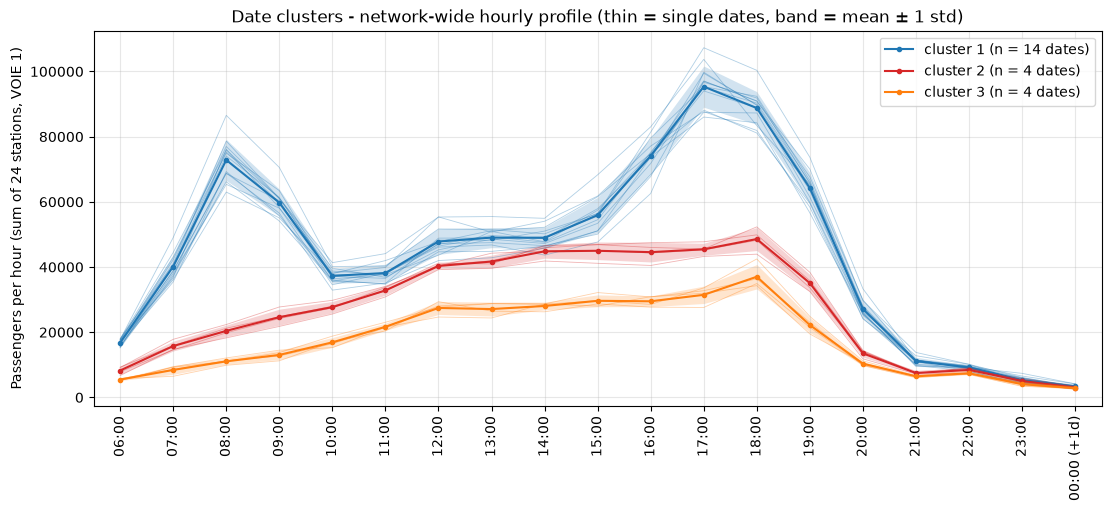

Mean daily total (19 hours, VOIE 1) per cluster:
       mean      std       min       max
1  845343.0  42292.0  783738.0  938577.0
2  512473.0  26173.0  473260.0  527009.0
3  340068.0  15732.0  324302.0  359091.0


In [20]:
# Cluster profiles: network-wide hourly profile (sum of the 24 stations) of each date cluster
DATE_COLORS = ["tab:blue", "tab:red", "tab:orange", "tab:green", "tab:purple"]
net_by_date = X_dates.reshape(len(DATES_2), S, T).sum(axis=1)       # dates x hours

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
xs = np.arange(T)
for c in range(1, K_DATES + 1):
    sel = labels_dates == c
    for row in net_by_date[sel]:
        ax.plot(xs, row, color=DATE_COLORS[c - 1], lw=0.6, alpha=0.35)             # each date
    st = pd.DataFrame({"mean": net_by_date[sel].mean(axis=0),
                       "std": net_by_date[sel].std(axis=0, ddof=1) if sel.sum() > 1 else np.nan})
    plot_band(ax, st, f"cluster {c} (n = {sel.sum()} dates)", DATE_COLORS[c - 1])      # mean +/- 1 std
set_hour_axis(ax, H19)
ax.set_ylabel("Passengers per hour (sum of 24 stations, VOIE 1)")
ax.set_title("Date clusters - network-wide hourly profile (thin = single dates, band = mean ± 1 std)")
ax.legend()
save_fig(fig, "2_1_cluster_profiles")
plt.show()

print("Mean daily total (19 hours, VOIE 1) per cluster:")
print(pd.Series(net_by_date.sum(axis=1)).groupby(labels_dates).agg(["mean", "std", "min", "max"]).round(0))

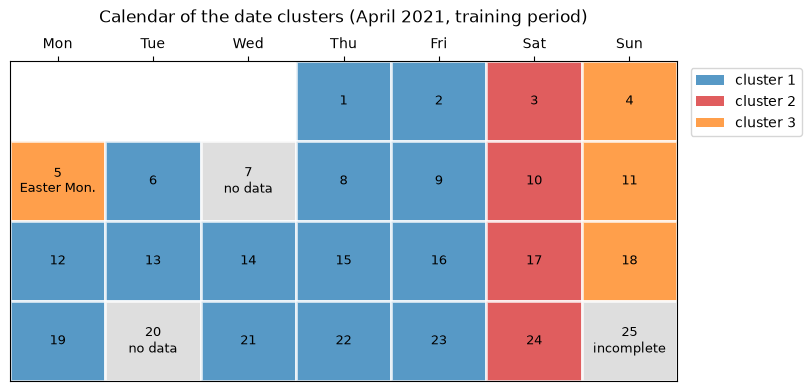

In [21]:
# Calendar distribution of the date types (grey = date not retained)
def plot_calendar(labels_by_date, colors):
    first = TRAIN_DATES[0]
    fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
    for d in TRAIN_DATES:
        row, col = divmod((d - first).days + first.day_of_week, 7)
        if d in labels_by_date.index:
            face, txt = colors[labels_by_date[d] - 1], f"{d.day}"
        else:
            face, txt = "lightgrey", f"{d.day}\n" + ("no data" if d in missing_dates else "incomplete")
        if d == pd.Timestamp("2021-04-05"):
            txt += "\nEaster Mon."
        ax.add_patch(plt.Rectangle((col, row), 1, 1, facecolor=face, edgecolor="white", lw=2, alpha=0.75))
        ax.text(col + 0.5, row + 0.5, txt, ha="center", va="center", fontsize=9)
    ax.set_xlim(0, 7)
    ax.set_ylim(((TRAIN_DATES[-1] - first).days + first.day_of_week) // 7 + 1, 0)      # number of weeks, top to bottom
    ax.set_xticks(np.arange(7) + 0.5, WEEKDAY_NAMES)
    ax.set_yticks([])
    ax.xaxis.tick_top()
    ax.grid(False)
    ax.set_title("Calendar of the date clusters (April 2021, training period)", pad=28)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=colors[c - 1], alpha=0.75, label=f"cluster {c}")
                       for c in sorted(labels_by_date.unique())], loc="upper left", bbox_to_anchor=(1.01, 1))
    return fig


fig = plot_calendar(DATE_CLUSTERS, DATE_COLORS)
save_fig(fig, "2_1_calendar")
plt.show()

In [22]:
# Check: same clustering but keeping only the shape (each date divided by its own total)?
X_dates_shape = X_dates / X_dates.sum(axis=1, keepdims=True)
Z_dates_shape = linkage(X_dates_shape, method="ward", metric="euclidean")
for k in [2, 3, 4]:
    ari = adjusted_rand_score(fcluster(Z_dates, k, criterion="maxclust"), fcluster(Z_dates_shape, k, criterion="maxclust"))
    print(f"k = {k}: adjusted Rand index raw vs shape-only = {ari:.2f}")

lab_shape = relabel_by_volume(fcluster(Z_dates_shape, 3, criterion="maxclust"), X_dates)
print("\nShape-only partition, k = 3:")
for c in range(1, 4):
    print(f"  cluster {c}:", ", ".join(date_names[lab_shape == c]))

k = 2: adjusted Rand index raw vs shape-only = 1.00
k = 3: adjusted Rand index raw vs shape-only = 0.50
k = 4: adjusted Rand index raw vs shape-only = 0.53

Shape-only partition, k = 3:
  cluster 1: Thu 01/04, Tue 06/04, Thu 08/04, Mon 12/04, Tue 13/04, Wed 14/04, Thu 15/04, Mon 19/04, Wed 21/04, Thu 22/04
  cluster 2: Fri 02/04, Fri 09/04, Fri 16/04, Fri 23/04
  cluster 3: Sat 03/04, Sun 04/04, Mon 05/04, Sat 10/04, Sun 11/04, Sat 17/04, Sun 18/04, Sat 24/04


In [23]:
# Why do the Fridays separate when only the shape is kept? Share of the daily total in each hour, Fridays vs Mon-Thu (cluster 1 dates)
share = net_by_date / net_by_date.sum(axis=1, keepdims=True) * 100
in_c1 = labels_dates == 1
is_fri = np.asarray(DATES_2.day_of_week == 4)
cmp_fri = pd.DataFrame({"Mon-Thu": share[in_c1 & ~is_fri].mean(axis=0),
                        "Fri": share[in_c1 & is_fri].mean(axis=0)}, index=[hour_label(h) for h in H19])
cmp_fri["Fri - Mon-Thu"] = cmp_fri["Fri"] - cmp_fri["Mon-Thu"]
print("Share of the daily total (%), cluster 1 dates:")
print(cmp_fri.loc[["07:00", "08:00", "12:00", "14:00", "15:00", "17:00", "18:00", "19:00"]].round(2).to_string())

Share of the daily total (%), cluster 1 dates:
       Mon-Thu    Fri  Fri - Mon-Thu
07:00     4.79   4.62          -0.17
08:00     8.85   8.02          -0.83
12:00     5.46   6.15           0.69
14:00     5.61   6.25           0.63
15:00     6.33   7.33           0.99
17:00    11.45  10.83          -0.62
18:00    10.78   9.83          -0.95
19:00     7.78   7.11          -0.67


**Observations**
- Retained data: 22 dates (15 weekdays, 7 weekend days) × 24 stations × 19 hours, so `X_dates` is 22 × 456 with no missing value. Excluded: 7 and 20 April (no record) and 25 April (station 12 incomplete).
- The dendrogram has one very large jump (Ward distance ≈ 84 000) that separates the weekdays from the weekend, then a second one (≈ 19 800) that splits the weekend group; everything below ≈ 11 000 is small. Quantitatively, k = 2 has the best silhouette (0.78) but k = 3 is almost as good (0.75) and has the best Davies–Bouldin index (0.32). From k = 4 the silhouette falls to 0.47. The within-cluster share of the total variance goes from 10.6 % (k = 2) to 5.6 % (k = 3) and 4.1 % (k = 4). So we keep **k = 3**.
- The three clusters are exactly: **cluster 1** = the 14 ordinary weekdays (mean daily total ≈ 845 000 pass.), **cluster 2** = the 4 Saturdays (≈ 512 000), **cluster 3** = the 3 Sundays **and Easter Monday** (≈ 340 000). Saturdays are about 61 % of a weekday and Sundays about 40 %. The calendar shows no other exception: every date follows its day of the week, except 5 April.
- Network profiles: cluster 1 has the two commuting peaks (≈ 73 000 at 08:00 and ≈ 95 000 at 17:00, the afternoon peak being stronger); clusters 2 and 3 have no morning peak, rise slowly to a plateau and peak at 18:00 (≈ 49 000 and ≈ 37 000). After 21:00 the three profiles are almost the same.
- Spread inside the clusters is small compared with the gaps between them: the mean distance to the centre is 6–9 % of the norm of the centre (7.3 % / 6.4 % / 8.7 %). Cluster 1 holds 88 % of the within-cluster variation simply because it has 14 dates; its dates also differ more in volume (std of the daily total ≈ 42 000 vs ≈ 26 000 and ≈ 16 000).
- k = 4 only isolates 1 and 2 April (the two highest days, already noticed in 1.1); they are not different enough to be a separate type at k = 3.
- Check with shape only (each date divided by its total): k = 2 is identical (adjusted Rand index 1.00), so the weekday / weekend split does not depend on the representation. For k = 3 the index is 0.50: Saturdays, Sundays and Easter Monday stay together, and the Fridays are separated from Monday–Thursday. Fridays have a flatter day: about 0.6–1 point less of the daily total at 08:00 and 17:00–19:00 and 0.6–1 point more between 12:00 and 15:00. So the Saturday / Sunday split of our k = 3 is a *volume* effect, while the Friday effect is a *shape* effect that the volume hides.

**Possible explanations:** Saturday is a day of shopping / leisure trips, Sunday and public holidays have even fewer trips, which would explain why Easter Monday joins the Sundays. The flatter Fridays could come from more teleworking or earlier departures at the end of the week. These are hypotheses, the data only gives counts. With only 4 Saturdays and 4 Sunday-like dates, the variability of clusters 2 and 3 is estimated on very few dates.

## 2.2 Cluster stations

Representation: for each station $s$, the mean weekday profile and the mean weekend profile over the retained training dates, put one after the other,
$z_s = (\mu_{s,wd,1},\dots,\mu_{s,wd,T},\ \mu_{s,we,1},\dots,\mu_{s,we,T}) \in \mathbb{R}^{2T}$, again in raw passengers per hour. This keeps the three things Section 1 found: the station level (1.3), the weekday / weekend contrast (1.4) and the shape of the day, in particular the morning / afternoon balance. We use the same 22 retained dates as in 2.1 (15 weekdays, 7 weekend days), so there is no missing value and no imputation. Weekdays and weekends are defined by the calendar as in Section 1, which means Easter Monday is counted as a weekday here (checked below).

In [24]:
def mean_by_station(prof, dates):
    # mean profile of every station over the given dates (rows = stations, columns = hours)
    return prof[prof.index.get_level_values("op_date").isin(dates)].groupby(level="station").mean()


mu_wd = mean_by_station(prof_all, dates_of_type(DATES_2, "weekday"))
mu_we = mean_by_station(prof_all, dates_of_type(DATES_2, "weekend"))
assert list(mu_wd.index) == STATIONS

Z_stations = np.hstack([mu_wd.to_numpy(), mu_we.to_numpy()])
print(f"Z_stations: S = {Z_stations.shape[0]} stations x 2T = 2*{T} = {2 * T} columns -> shape {Z_stations.shape}")
print("Missing values:", int(np.isnan(Z_stations).sum()))

station_names = np.array([f"S{s}" for s in STATIONS])
Zl_stations = linkage(Z_stations, method="ward", metric="euclidean")
scores_stations = candidate_scores(Z_stations, Zl_stations, range(2, 9))
print(scores_stations.round(3).to_string())

Z_stations: S = 24 stations x 2T = 2*19 = 38 columns -> shape (24, 38)
Missing values: 0
   silhouette  calinski_harabasz  davies_bouldin  within_share  merge_height                     sizes
k                                                                                                     
2       0.557             43.372           0.654         0.337     17613.698                   [16, 8]
3       0.529             52.691           0.459         0.166      8925.753                [16, 5, 3]
4       0.416             56.084           0.763         0.106      5293.418             [10, 6, 5, 3]
5       0.439             56.247           0.696         0.078      3642.184           [6, 6, 5, 4, 3]
6       0.481             60.821           0.617         0.056      3206.669        [6, 5, 4, 3, 3, 3]
7       0.493             63.391           0.554         0.043      2474.841     [5, 4, 4, 3, 3, 3, 2]
8       0.457             72.439           0.489         0.031      2388.070  [5, 4, 4,

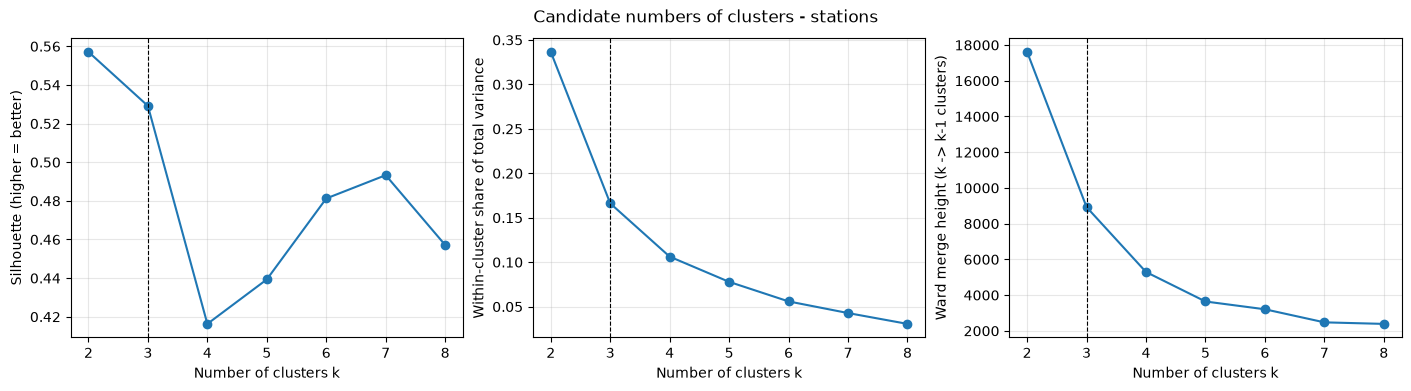

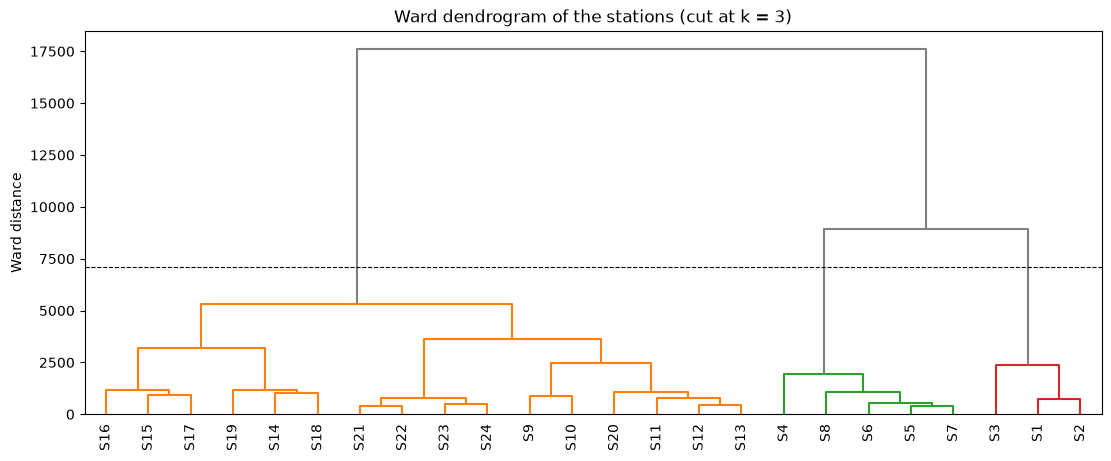

         size  mean_dist_to_centre  relative_spread  share_of_within_SS                                                                        members
cluster                                                                                                                                               
1          16             1361.228            0.113               0.851  S9, S10, S11, S12, S13, S14, S15, S16, S17, S18, S19, S20, S21, S22, S23, S24
2           5              600.830            0.071               0.069                                                             S4, S5, S6, S7, S8
3           3              924.896            0.236               0.080                                                                     S1, S2, S3


In [25]:
K_STATIONS = 3     # k = 3 is required for Section 3, the table above shows that it is also reasonable

fig = plot_scores(scores_stations, K_STATIONS, "Candidate numbers of clusters - stations")
save_fig(fig, "2_2_scores")
plt.show()

fig, ax = plot_dendrogram(Zl_stations, station_names, K_STATIONS, f"Ward dendrogram of the stations (cut at k = {K_STATIONS})")
save_fig(fig, "2_2_dendrogram")
plt.show()

labels_stations = relabel_by_volume(fcluster(Zl_stations, K_STATIONS, criterion="maxclust"), Z_stations)
STATION_CLUSTERS = pd.Series(labels_stations, index=STATIONS, name="station_cluster")      # kept for Section 3
print(cluster_summary(Z_stations, labels_stations, station_names).round(3).to_string())

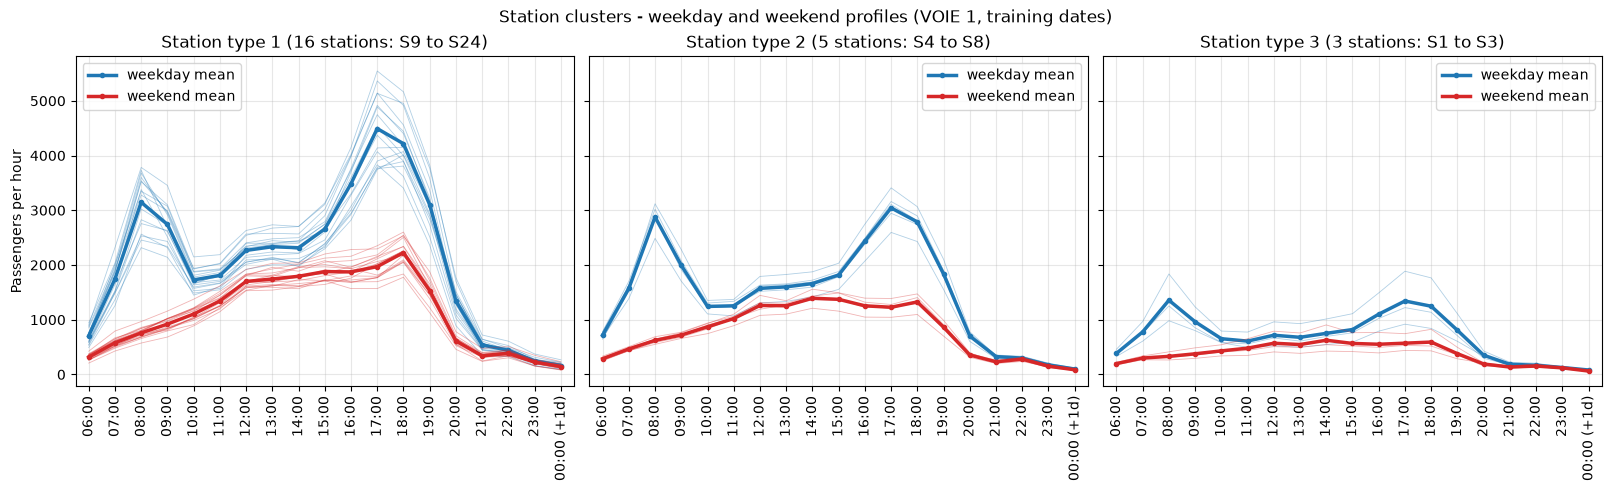

                       daily_sum am_peak_hour  am_peak pm_peak_hour  pm_peak  am_pm_ratio
station_type day_type                                                                    
1            weekday    39475.47        08:00  3146.10        17:00  4492.15         0.70
             weekend    21450.57        11:00  1343.96        18:00  2226.06         0.60
2            weekday    28008.97        08:00  2877.68        17:00  3043.51         0.95
             weekend    15040.63        11:00  1021.54        14:00  1392.40         0.73
3            weekday    13122.02        08:00  1356.44        17:00  1342.00         1.01
             weekend     7180.86        11:00   480.19        14:00   625.29         0.77


In [26]:
# Characteristic curves: mean weekday / weekend profile of each station type (thin = single stations)
fig, axes = plt.subplots(1, K_STATIONS, figsize=(16, 4.8), sharey=True, constrained_layout=True)
for c, ax in zip(range(1, K_STATIONS + 1), axes):
    sel = labels_stations == c
    for kind, mu in [("weekday", mu_wd), ("weekend", mu_we)]:
        for row in mu.to_numpy()[sel]:
            ax.plot(np.arange(T), row, color=DAYTYPE_COLORS[kind], lw=0.6, alpha=0.35)
        ax.plot(np.arange(T), mu.to_numpy()[sel].mean(axis=0), color=DAYTYPE_COLORS[kind], lw=2.5, marker="o", ms=3,
                label=f"{kind} mean")
    set_hour_axis(ax, H19)
    ax.set_title(f"Station type {c} ({sel.sum()} stations: S{STATIONS[np.where(sel)[0][0]]} to S{STATIONS[np.where(sel)[0][-1]]})")
    ax.legend()
axes[0].set_ylabel("Passengers per hour")
fig.suptitle("Station clusters - weekday and weekend profiles (VOIE 1, training dates)")
save_fig(fig, "2_2_station_clusters")
plt.show()

# peak summary of the mean profiles of each station type (same helper as in Section 1)
type_profiles = pd.DataFrame({(c, kind): mu.to_numpy()[labels_stations == c].mean(axis=0)
                              for c in range(1, K_STATIONS + 1) for kind, mu in [("weekday", mu_wd), ("weekend", mu_we)]},
                             index=H19).T
type_profiles.index.names = ["station_type", "day_type"]
print(peak_summary(type_profiles, H19).round(2).to_string())

In [27]:
# Checks on the station partition: (a) shape only (each z_s divided by its maximum), (b) without Easter Monday
Z_shape = Z_stations / Z_stations.max(axis=1, keepdims=True)
Zl_shape = linkage(Z_shape, method="ward", metric="euclidean")

wd_no_easter = dates_of_type(DATES_2, "weekday").difference([pd.Timestamp("2021-04-05")])
Z_no_easter = np.hstack([mean_by_station(prof_all, wd_no_easter).to_numpy(), mu_we.to_numpy()])
Zl_no_easter = linkage(Z_no_easter, method="ward", metric="euclidean")

base = fcluster(Zl_stations, K_STATIONS, criterion="maxclust")
for name, Zl in [("shape only", Zl_shape), ("without Easter Monday", Zl_no_easter)]:
    other = fcluster(Zl, K_STATIONS, criterion="maxclust")
    print(f"k = {K_STATIONS}: adjusted Rand index raw vs {name} = {adjusted_rand_score(base, other):.2f}")

lab_shape_st = fcluster(Zl_shape, K_STATIONS, criterion="maxclust")
print("\nShape-only partition, k = 3:")
for c in np.unique(lab_shape_st):
    print(f"  group {c}:", ", ".join(station_names[lab_shape_st == c]))
print("Silhouette of the shape-only partition:", round(silhouette_score(Z_shape, lab_shape_st), 3))

k = 3: adjusted Rand index raw vs shape only = 0.16
k = 3: adjusted Rand index raw vs without Easter Monday = 1.00

Shape-only partition, k = 3:
  group 1: S1, S2, S3, S4, S5, S6, S7, S8, S9, S10, S11
  group 2: S15, S16, S17, S18
  group 3: S12, S13, S14, S19, S20, S21, S22, S23, S24
Silhouette of the shape-only partition: 0.427


**Observations**
- `Z_stations` is 24 × 38 (24 stations, 19 weekday means then 19 weekend means), with no missing value. Means are computed over the 15 retained weekdays and the 7 retained weekend days.
- Criteria: silhouette 0.56 (k = 2) and 0.53 (k = 3), lower for k = 4–5 (0.42–0.44) and a bit higher again for k = 6–7 (0.48–0.49) but with clusters of only 3 stations. Davies–Bouldin is the best at k = 3 (0.46). Calinski–Harabasz keeps increasing with k (43 → 72), so it does not help. The Ward heights drop from ≈ 17 600 (2 → 1) and ≈ 8 900 (3 → 2) to ≈ 5 300 (4 → 3), so k = 3 is a reasonable cut. The within-cluster share of the variance is 33.7 % for k = 2 and 16.6 % for k = 3.
- The k = 3 partition is made of **consecutive station numbers**: type 1 = S9–S24 (16 stations), type 2 = S4–S8 (5), type 3 = S1–S3 (3). It orders the stations by demand level: mean weekday daily sum ≈ 39 500 / 28 000 / 13 100 passengers.
- Weekday shape: all types have a morning peak at 08:00 and an afternoon peak at 17:00, but the AM/PM ratio goes from 0.70 (type 1, strong afternoon peak) to 0.95 (type 2) and 1.01 (type 3, balanced peaks). This is the same gradient as in 1.3.
- Weekend: no morning peak in any type, a slow rise to a plateau (peak at 14:00–18:00), and the weekend daily sum is ≈ 54–55 % of the weekday one for the three types. So the weekday / weekend contrast does not discriminate between the types; the level and the AM/PM balance do.
- Spread: type 3 has the largest relative spread (0.24) and type 2 the smallest (0.07). Type 1 holds 85 % of the within-cluster variation because it is large and not homogeneous: in 1.3 its stations have AM/PM ratios from ≈ 0.48 (S16) to ≈ 0.84 (S9).
- Checks: without Easter Monday in the weekday mean, the partition is identical (adjusted Rand index 1.00). With a shape-only representation (each $z_s$ divided by its maximum) the partition is very different (index 0.16, silhouette 0.43): {S1–S11}, {S15–S18}, {S12–S14, S19–S24}, i.e. it groups the stations by AM/PM balance and not by size. So our raw-count partition is mostly a **size** partition.

**Possible explanations:** type 3 could be small stations with balanced peaks (mixed residential and activity use) and type 1 large stations where VOIE 1 is mostly used for the evening return; the small stations of type 3 probably also have noisier curves, which would explain their larger relative spread. If station numbers follow the line, this would explain why the clusters are contiguous, but line geometry and land use are not in the data. k = 4 would separate S14–S19 from the other stations of type 1 (silhouette 0.42), which could be interesting for the interpretation but is not better supported by the criteria, so we keep k = 3 as required for Section 3.

## 2.3 Interpret and connect the two partitions

To connect the two clusterings we look at each station type on each date type: the profile of a station type on a date type is the mean over the dates of that type and over the stations of that type (so the curves are in passengers per station and per hour and can be compared between types of different size).

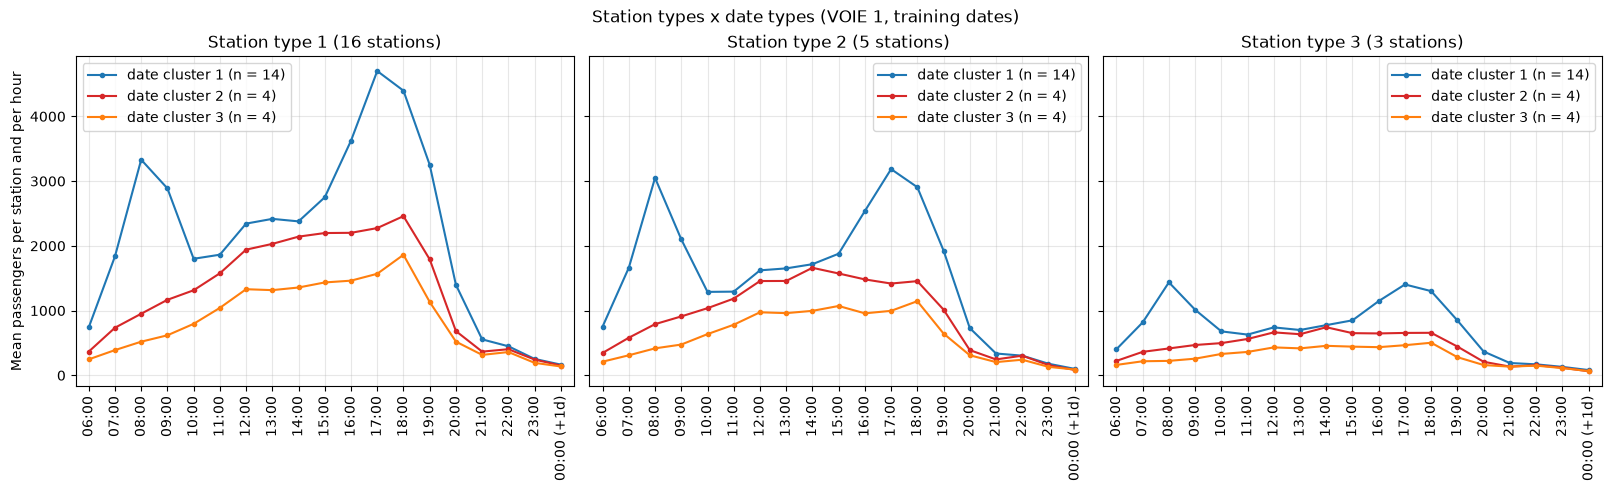

                           daily_sum am_peak_hour  am_peak pm_peak_hour  pm_peak  am_pm_ratio  level_vs_cluster1
station_type date_cluster                                                                                       
1            1              41138.52        08:00  3330.51        17:00  4700.44         0.71               1.00
             2              24990.66        11:00  1575.91        18:00  2458.67         0.64               0.61
             3              16596.03        11:00  1041.61        18:00  1861.33         0.56               0.40
2            1              29217.94        08:00  3049.60        17:00  3185.27         0.96               1.00
             2              17544.05        11:00  1185.05        14:00  1660.75         0.71               0.60
             3              11547.90        11:00   781.20        18:00  1145.15         0.68               0.40
3            1              13678.88        08:00  1436.21        17:00  1403.57         1.02   

In [28]:
A = X_dates.reshape(len(DATES_2), S, T)       # dates x stations x hours
st_types, dt_types = sorted(np.unique(labels_stations)), sorted(np.unique(labels_dates))

curves = {(sc, dc): A[labels_dates == dc][:, labels_stations == sc, :].mean(axis=(0, 1))
          for sc in st_types for dc in dt_types}

fig, axes = plt.subplots(1, len(st_types), figsize=(16, 4.8), sharey=True, constrained_layout=True)
for sc, ax in zip(st_types, axes):
    for dc in dt_types:
        ax.plot(np.arange(T), curves[(sc, dc)], marker="o", ms=3, color=DATE_COLORS[dc - 1],
                label=f"date cluster {dc} (n = {(labels_dates == dc).sum()})")
    set_hour_axis(ax, H19)
    ax.set_title(f"Station type {sc} ({(labels_stations == sc).sum()} stations)")
    ax.legend()
axes[0].set_ylabel("Mean passengers per station and per hour")
fig.suptitle("Station types x date types (VOIE 1, training dates)")
save_fig(fig, "2_3_station_types_by_date_type")
plt.show()

cross = pd.DataFrame(curves, index=H19).T
cross.index.names = ["station_type", "date_cluster"]
table = peak_summary(cross, H19)
# daily level of each date cluster relative to date cluster 1 (same station type)
table["level_vs_cluster1"] = table["daily_sum"] / table["daily_sum"].groupby(level="station_type").transform("first")
print(table.round(2).to_string())

print("\nStations of each type:")
for sc in st_types:
    print(f"  type {sc}:", ", ".join(station_names[labels_stations == sc]))

**Observations**
- The two partitions describe different things. **Dates** are grouped by the weekly rhythm (weekday / Saturday / Sunday-holiday), mostly through the *volume*, which confirms 1.2 (weekend ≈ 52–54 % of a weekday) and 1.4. **Stations** are grouped by their *level* and by the AM/PM balance, which confirms 1.3 (level differences of a factor ≈ 5, gradient of the AM/PM ratio with the station number).
- They are almost independent in volume: relative to the weekday cluster, Saturdays are at 0.60–0.61 and Sundays / Easter Monday at 0.40–0.41 for **each** of the three station types. The date type changes the demand of every station by about the same factor.
- What the date type changes in the *shape* is the morning peak: on weekdays all three station types have it (at 08:00, ≈ 3 300 / 3 050 / 1 400 pass./h per station), on Saturdays and Sundays it disappears everywhere and is replaced by a slow rise to a maximum at 14:00–18:00. The evening drop after 19:00 is common to all types and dates.
- What the station type changes is how strong the weekday afternoon peak is compared with the morning one (AM/PM ≈ 0.71 for type 1, 0.96 for type 2, 1.02 for type 3). On weekends this ratio is lower for all types (≈ 0.56–0.76), but there the "morning peak" is only the late-morning level (11:00), not a real peak.
- The large stations (type 1) show the strongest commuting pattern in absolute value (≈ 4 700 pass./h at 17:00 on weekdays against ≈ 2 500 at the Saturday maximum), but in relative value the weekend drop is the same as for the small stations.
- Preferred partitions: for the dates **k = 3** (weekday / Saturday / Sunday and holiday), supported by the silhouette, the Davies–Bouldin index, the dendrogram heights and Section 1; k = 2 is the simpler alternative with the best silhouette. For the stations we keep **k = 3** (required for Section 3, and supported by the Davies–Bouldin index and the dendrogram), keeping in mind that with the raw representation it mainly means "small / medium / large station". A shape-based version would give a different partition (see 2.2).

**Possible explanations:** the near-constant weekend factor across stations suggests that the weekly rhythm is a network-wide effect (work and school calendar, Easter holiday, restrictions in force), while the differences between stations would come from where they are along the line and what surrounds them, which we cannot check here. The clusters of dates 2 and 3 are based on 4 dates each, so these conclusions should be read with care.